# 54. Hypoxia Frequency and Trend Across Basins

This notebook visualizes the spatial distribution and temporal trends of Dissolved Oxygen (DO) across Tokyo Bay, Ise Bay, and each of the individual sub-basins within the Seto Inland Sea.

Sections:
1. Yearly Mean DO Distribution Map
2. Hypoxia Frequency Maps (Hypoxic vs. Low DO)
3. Number of Hypoxic Stations Summary
4. DO Trend and Severity Spatial Mapping

In [1]:
import pandas as pd
import numpy as np
import geopandas as gpd
from shapely.geometry import Point
from shapely.prepared import prep
from scipy import ndimage
from scipy.spatial import cKDTree
from pyproj import Transformer
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.collections import PatchCollection
import sys
from pathlib import Path
import warnings
from scipy import stats

warnings.filterwarnings('ignore')

# Project Path Setup
project_root = Path.cwd().parent
if str(project_root) not in sys.path:
    sys.path.append(str(project_root))

from scripts.paths import ProjectPaths
from scripts.mapping_config import MappingConfig
from scripts.data_loader import load_and_process_data

# Setup global mapping config
MappingConfig.apply_global_plot_styles()

In [2]:
# Constants for diffusion interpolation
GRID_RES = 1000  # finer grid res to account for sub-basins
MAX_ITERS = 500
TOL = 1e-3
OMEGA = 1.8

# Load the pre-processed data
merged_gdf = load_and_process_data(force_reload=False)

TARGET_SEASON = 'Summer'
SAISUIPOIN_ID = 2

summer_bottom_df = merged_gdf[
    (merged_gdf['season'] == TARGET_SEASON) & 
    (merged_gdf['saisuipoin'] == SAISUIPOIN_ID)
].copy()

summer_bottom_df['do_'] = pd.to_numeric(summer_bottom_df['do_'], errors='coerce')
summer_bottom_df = summer_bottom_df.dropna(subset=['do_'])

print(f"Total observations: {len(summer_bottom_df)}")

# Define regions
sis_df = summer_bottom_df[summer_bottom_df['watermass_name'] == 'Seto Inland Sea']
sis_divisions = sis_df['division'].dropna().unique().tolist()

regions_info = []

regions_info.append({
    'name': 'Tokyo Bay',
    'land_boundary': ProjectPaths.BOUNDARIES_DIR / 'SIS_prefecture_boundaries' / 'Tokyobay_boundary.shp',
    'water_mask': ProjectPaths.BOUNDARIES_DIR / 'SIS water mass polygon' / 'sea_area_mask_Tokyo.shp',
    'data': summer_bottom_df[summer_bottom_df['watermass_name'] == 'Tokyo Bay'].copy()
})

regions_info.append({
    'name': 'Ise Bay',
    'land_boundary': ProjectPaths.BOUNDARIES_DIR / 'SIS_prefecture_boundaries' / 'Isebay_boundary.shp',
    'water_mask': ProjectPaths.BOUNDARIES_DIR / 'SIS water mass polygon' / 'sea_area_mask_Ise.shp',
    'data': summer_bottom_df[summer_bottom_df['watermass_name'] == 'Ise Bay'].copy()
})

for div in sis_divisions:
    regions_info.append({
        'name': div,
        'land_boundary': ProjectPaths.BOUNDARIES_DIR / 'SIS_prefecture_boundaries' / 'Setonaikai_boundary_2.shp',
        'water_mask': ProjectPaths.BOUNDARIES_DIR / 'SIS water mass polygon' / 'sea_area_mask_sis_simplified.shp',
        'data': sis_df[sis_df['division'] == div].copy()
    })

print(f"Total regions defined: {len(regions_info)}")
for r in regions_info:
    print(f"{r['name']}: {len(r['data'])} observations")

Loading processed data from /home/reyha/SIS_Analysis_WSL/data/processed/merged_gdf.feather...


Total observations: 8033
Total regions defined: 14
Tokyo Bay: 1207 observations
Ise Bay: 1056 observations
Osaka Bay: 430 observations
Harima Nada: 605 observations
Iyo Nada: 654 observations
Suo Nada: 903 observations
Bisan Seto: 391 observations
Bingo Nada: 312 observations
Bungo Channel: 513 observations
Hibiki Nada: 129 observations
Kii Channel: 402 observations
Aki Nada: 301 observations
Hiroshima Bay: 350 observations
Hiuchi Nada: 391 observations


In [3]:
# Helper to build land patches
def build_land_patches(gdf, facecolor, edgecolor, linewidth):
    patches = []
    for geom in gdf.geometry:
        if geom.geom_type == 'Polygon':
            patches.append(MplPolygon(np.array(geom.exterior.coords), closed=True))
        elif geom.geom_type == 'MultiPolygon':
            for poly in geom.geoms:
                patches.append(MplPolygon(np.array(poly.exterior.coords), closed=True))
    return patches, facecolor, edgecolor, linewidth

def add_land_to_ax(ax, patches_data):
    patches, fc, ec, lw = patches_data
    ax.add_feature(cfeature.LAND, facecolor=MappingConfig.COLOR_LAND, zorder=MappingConfig.ZORDER_CARTOPY_LAND)
    ax.add_feature(cfeature.COASTLINE, linewidth=0.5, edgecolor='black', zorder=MappingConfig.ZORDER_CARTOPY_COASTLINE)
    pc = PatchCollection(
        [MplPolygon(p.get_xy(), closed=True) for p in patches],
        facecolor=fc, edgecolor=ec, linewidth=lw,
        transform=ccrs.PlateCarree(),
        zorder=MappingConfig.ZORDER_LAND
    )
    ax.add_collection(pc)

def setup_diffusion_grid(water_boundary_path, data_bounds, grid_res=GRID_RES):
    """Sets up the grid, KDTree, and masks for diffusion interpolation."""
    water_boundary = gpd.read_file(water_boundary_path)
    if water_boundary.crs != "EPSG:4326":
        water_boundary = water_boundary.to_crs("EPSG:4326")
        
    utm_crs = 'EPSG:32653'
    water_utm = water_boundary.to_crs(utm_crs)
    bounds_utm = water_utm.total_bounds
    
    data_bounds_gdf = gpd.GeoDataFrame({'geometry': [Point(data_bounds[0], data_bounds[1]), Point(data_bounds[2], data_bounds[3])]}, crs="EPSG:4326")
    data_bounds_utm = data_bounds_gdf.to_crs(utm_crs).total_bounds
    
    # Intersect bounds to keep grid tight around the specific region/sub-basin
    minx = max(bounds_utm[0], data_bounds_utm[0] - 5000)
    miny = max(bounds_utm[1], data_bounds_utm[1] - 5000)
    maxx = min(bounds_utm[2], data_bounds_utm[2] + 5000)
    maxy = min(bounds_utm[3], data_bounds_utm[3] + 5000)
    
    # Handle edge case where no intersection
    if minx >= maxx or miny >= maxy:
        return None
        
    grid_x_1d = np.arange(minx, maxx, grid_res)
    grid_y_1d = np.arange(miny, maxy, grid_res)
    grid_x, grid_y = np.meshgrid(grid_x_1d, grid_y_1d)
    
    water_polygon = water_utm.geometry.union_all()
    prepared_poly = prep(water_polygon)
    
    flat_x = grid_x.flatten()
    flat_y = grid_y.flatten()
    grid_points = [Point(x, y) for x, y in zip(flat_x, flat_y)]
    valid_points_mask = np.array([prepared_poly.contains(pt) for pt in grid_points])
    water_mask = valid_points_mask.reshape(grid_x.shape)
    
    transformer = Transformer.from_crs(utm_crs, "EPSG:4326", always_xy=True)
    lon_flat, lat_flat = transformer.transform(flat_x, flat_y)
    lon_wgs = lon_flat.reshape(grid_x.shape)
    lat_wgs = lat_flat.reshape(grid_y.shape)
    
    kernel = np.array([[0, 1, 0], [1, 0, 1], [0, 1, 0]])
    water_float = water_mask.astype(np.float64)
    W = ndimage.convolve(water_float, kernel, mode='constant', cval=0.0)
    valid_W_mask = W > 0
    
    i_indices, j_indices = np.indices(grid_x.shape)
    red_mask = (i_indices + j_indices) % 2 == 0
    black_mask = ~red_mask
    
    water_iy, water_ix = np.where(water_mask)
    if len(water_iy) == 0:
        return None
    water_coords = np.column_stack([grid_x[water_iy, water_ix], grid_y[water_iy, water_ix]])
    water_tree = cKDTree(water_coords)
    
    return {
        'grid_x': grid_x, 'grid_y': grid_y,
        'lon_wgs': lon_wgs, 'lat_wgs': lat_wgs,
        'water_mask': water_mask, 'valid_W_mask': valid_W_mask,
        'W': W, 'red_mask': red_mask, 'black_mask': black_mask,
        'water_tree': water_tree, 'water_iy': water_iy, 'water_ix': water_ix,
        'kernel': kernel,
        'utm_crs': utm_crs,
        'extent': [data_bounds[0]-0.05, data_bounds[2]+0.05, data_bounds[1]-0.05, data_bounds[3]+0.05]
    }

def run_diffusion_interpolation(do_vals, pts_x, pts_y, grid_info, max_iters=MAX_ITERS, tol=TOL, omega=OMEGA):
    water_mask = grid_info['water_mask']
    Z = np.full(water_mask.shape, np.nan)
    mean_val = np.nanmean(do_vals)
    Z[water_mask] = mean_val
    fixed_mask = np.zeros_like(water_mask, dtype=bool)

    station_coords = np.column_stack([pts_x, pts_y])
    _, nearest_idx = grid_info['water_tree'].query(station_coords)

    water_iy = grid_info['water_iy']
    water_ix = grid_info['water_ix']
    
    for k in range(len(do_vals)):
        iy = water_iy[nearest_idx[k]]
        ix = water_ix[nearest_idx[k]]
        Z[iy, ix] = do_vals[k]
        fixed_mask[iy, ix] = True

    Z_water = np.zeros_like(Z)
    kernel = grid_info['kernel']
    valid_W_mask = grid_info['valid_W_mask']
    W = grid_info['W']
    red_mask = grid_info['red_mask']
    black_mask = grid_info['black_mask']

    for it in range(max_iters):
        Z_old_water = Z[water_mask].copy()
        with np.errstate(divide='ignore', invalid='ignore'):
            Z_water[:] = 0.0
            Z_water[water_mask] = Z[water_mask]
            Z_sum = ndimage.convolve(Z_water, kernel, mode='constant', cval=0.0)
            Z_avg = np.where(valid_W_mask, Z_sum / W, Z)
            update_red = red_mask & water_mask & (~fixed_mask)
            Z[update_red] = (1 - omega) * Z[update_red] + omega * Z_avg[update_red]

            Z_water[:] = 0.0
            Z_water[water_mask] = Z[water_mask]
            Z_sum = ndimage.convolve(Z_water, kernel, mode='constant', cval=0.0)
            Z_avg = np.where(valid_W_mask, Z_sum / W, Z)
            update_black = black_mask & water_mask & (~fixed_mask)
            Z[update_black] = (1 - omega) * Z[update_black] + omega * Z_avg[update_black]

        max_diff = np.max(np.abs(Z[water_mask] - Z_old_water))
        if max_diff < tol:
            break

    return Z
import matplotlib.path as mpath
from matplotlib.patches import PathPatch

def gdf_to_clip_path(gdf, ax):
    """Convert a GeoDataFrame's geometry to a matplotlib Path for clipping on a GeoAxes."""
    union_geom = gdf.geometry.union_all()
    verts = []
    codes = []
    polys = [union_geom] if union_geom.geom_type == 'Polygon' else list(union_geom.geoms)
    for poly in polys:
        coords = np.array(poly.exterior.coords)
        verts.extend(coords)
        codes.append(mpath.Path.MOVETO)
        codes.extend([mpath.Path.LINETO] * (len(coords) - 2))
        codes.append(mpath.Path.CLOSEPOLY)
    return mpath.Path(verts, codes)


## 1. Yearly Mean DO Distribution Map (per basin)

Processing Yearly Mean DO for Tokyo Bay...


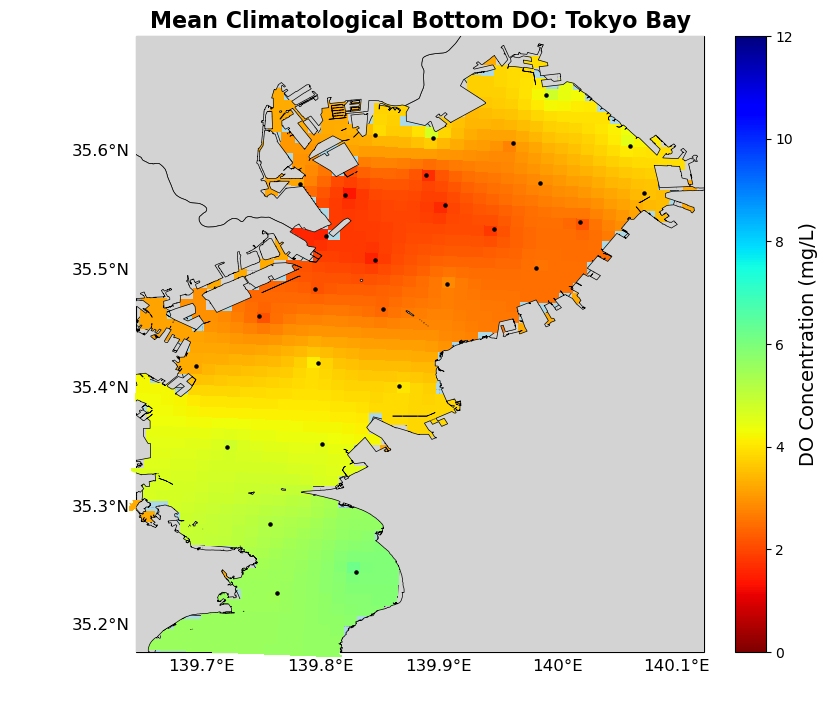

Processing Yearly Mean DO for Ise Bay...


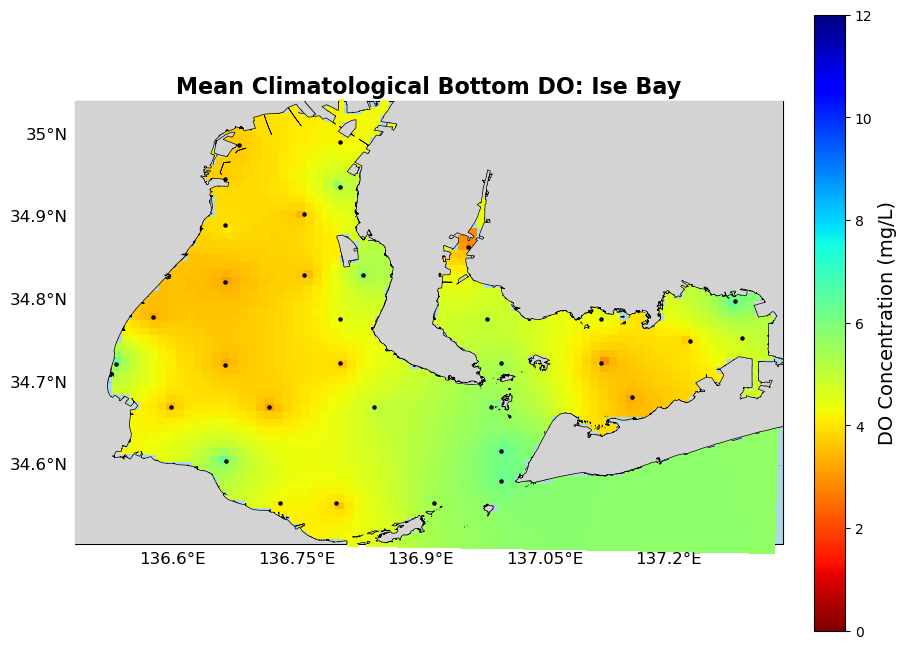

Processing Yearly Mean DO for Osaka Bay...


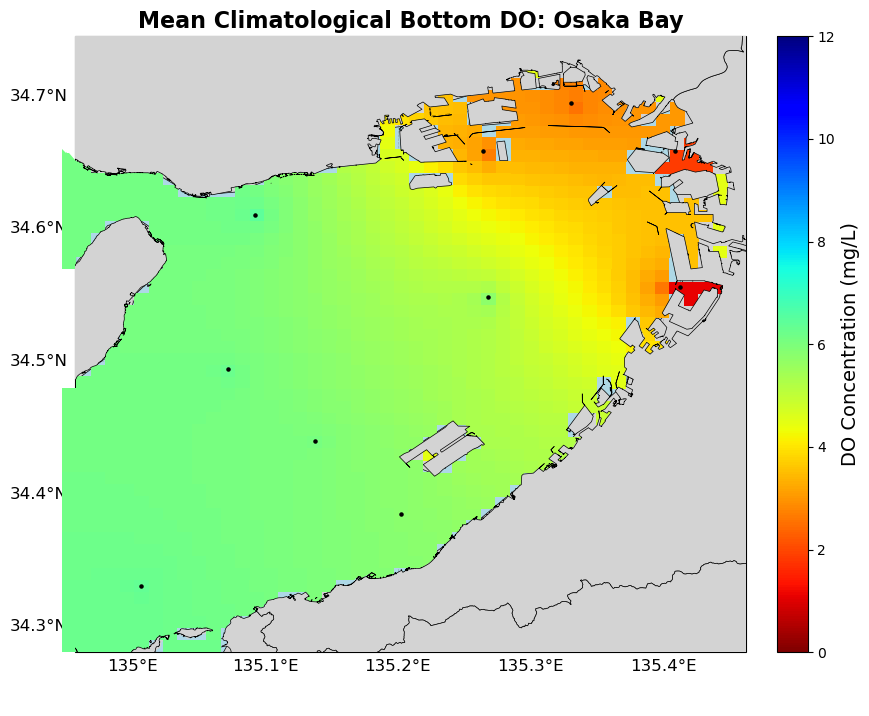

Processing Yearly Mean DO for Harima Nada...


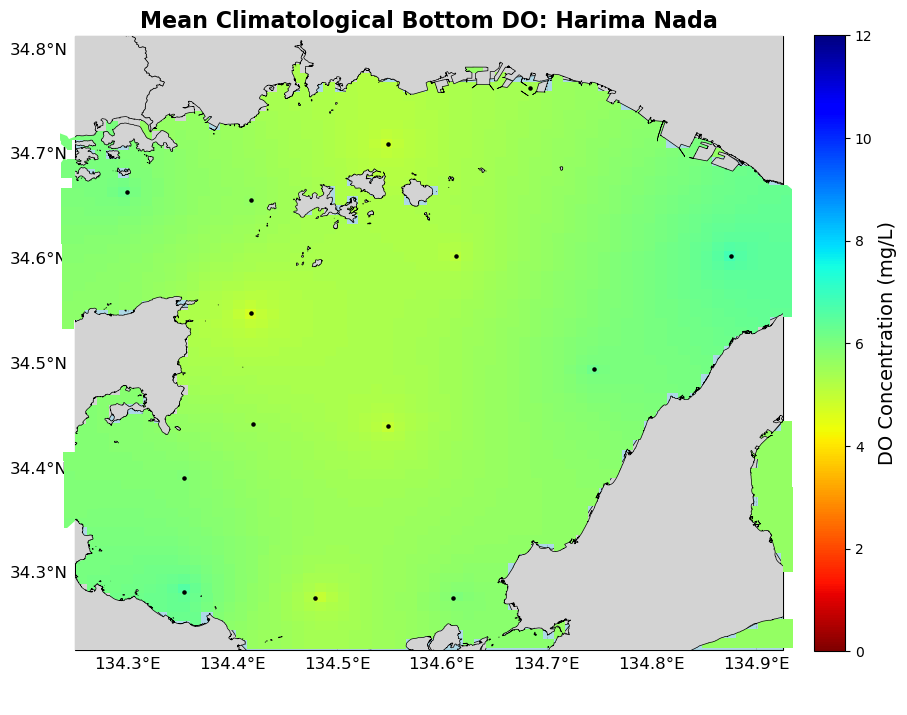

Processing Yearly Mean DO for Iyo Nada...


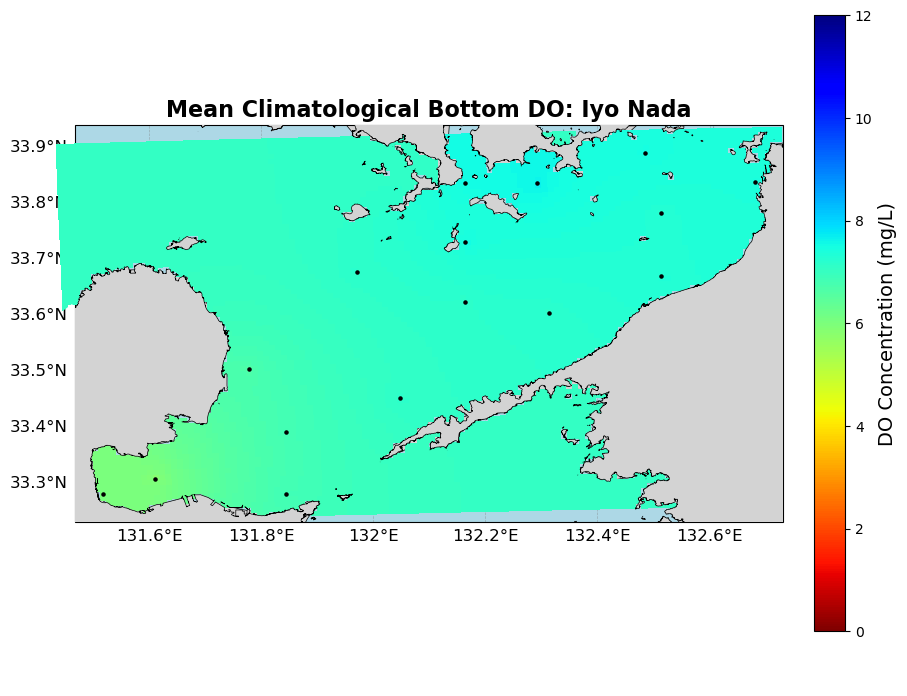

Processing Yearly Mean DO for Suo Nada...


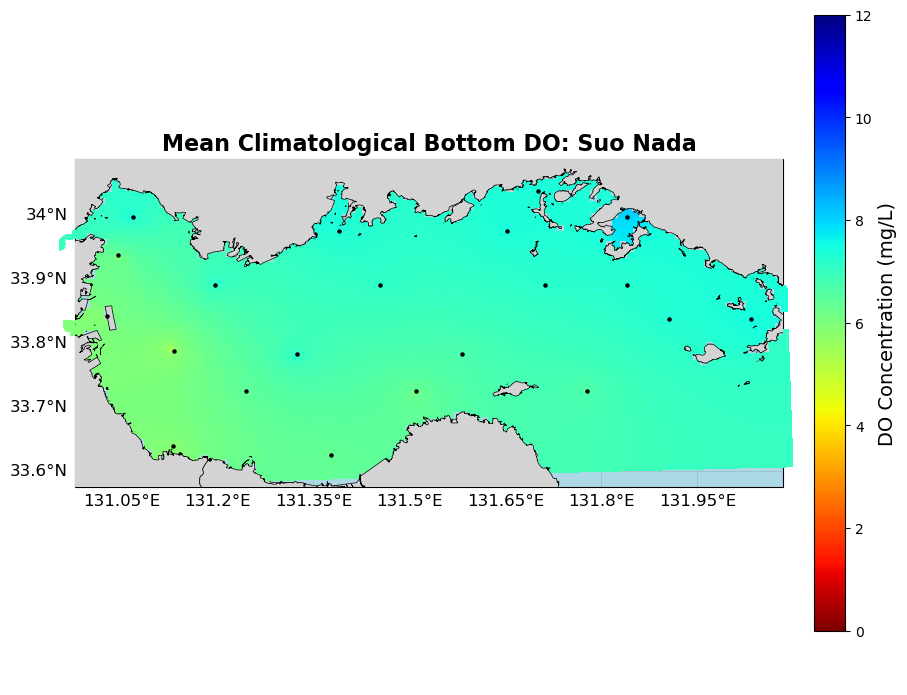

Processing Yearly Mean DO for Bisan Seto...


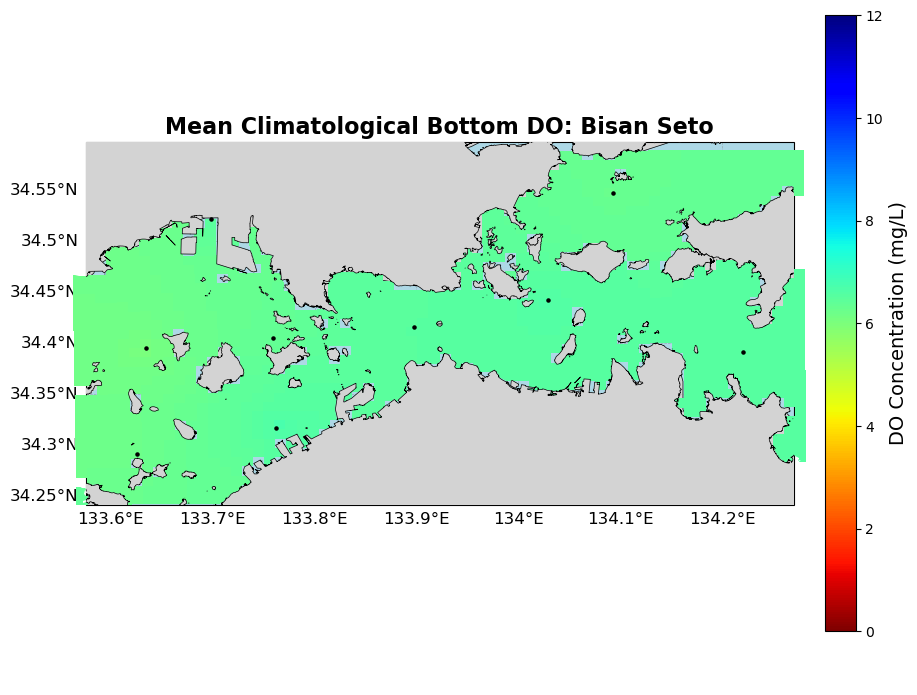

Processing Yearly Mean DO for Bingo Nada...


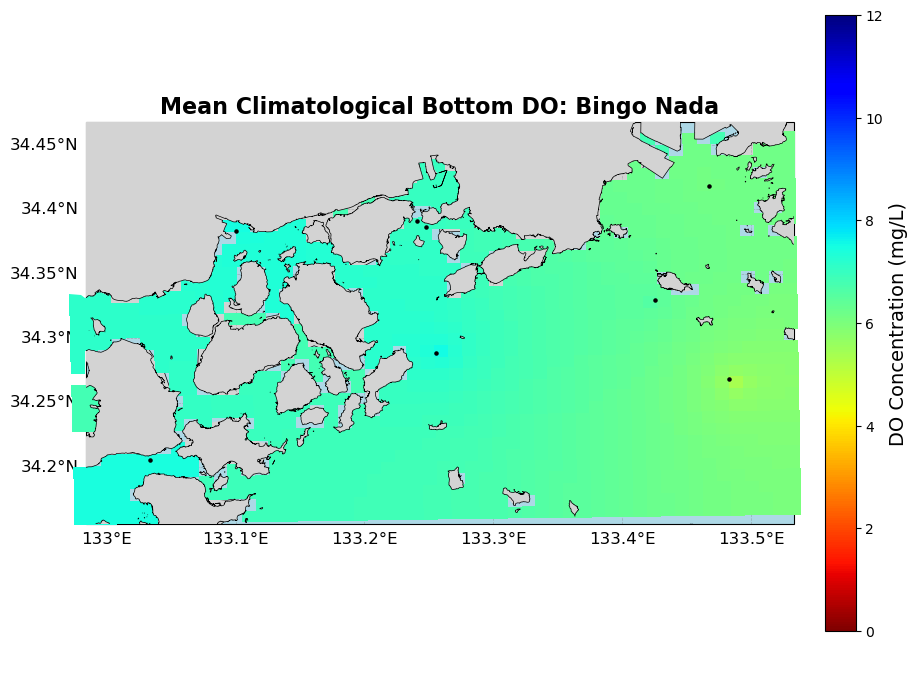

Processing Yearly Mean DO for Bungo Channel...


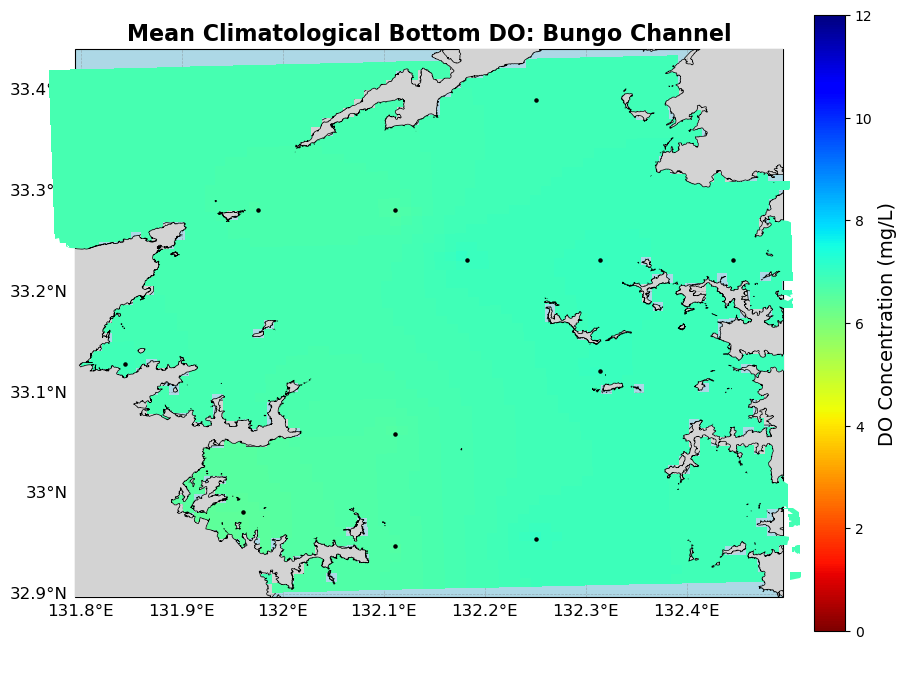

Processing Yearly Mean DO for Hibiki Nada...


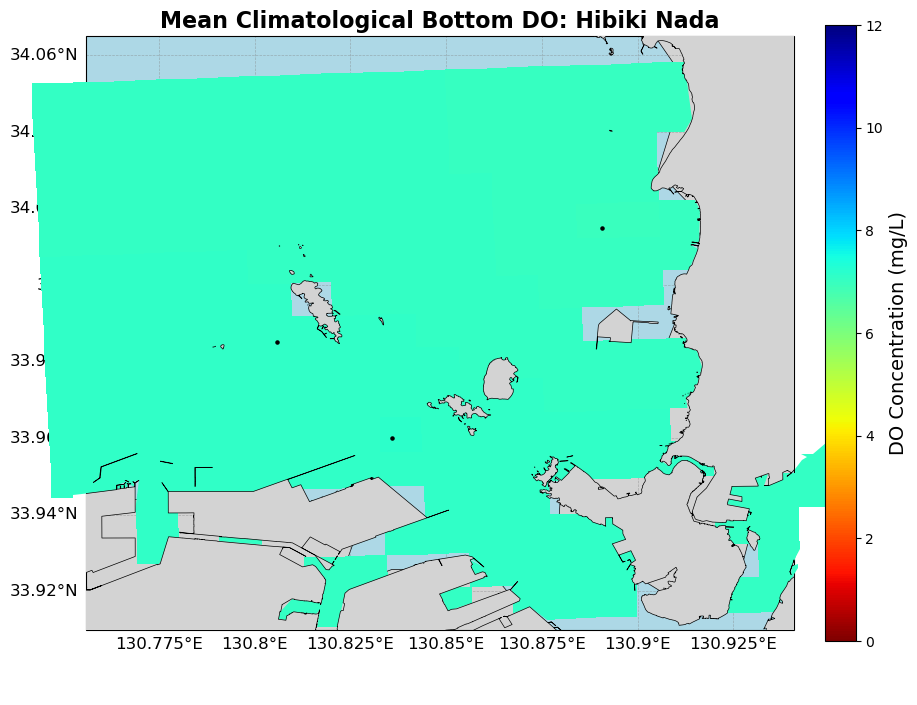

Processing Yearly Mean DO for Kii Channel...


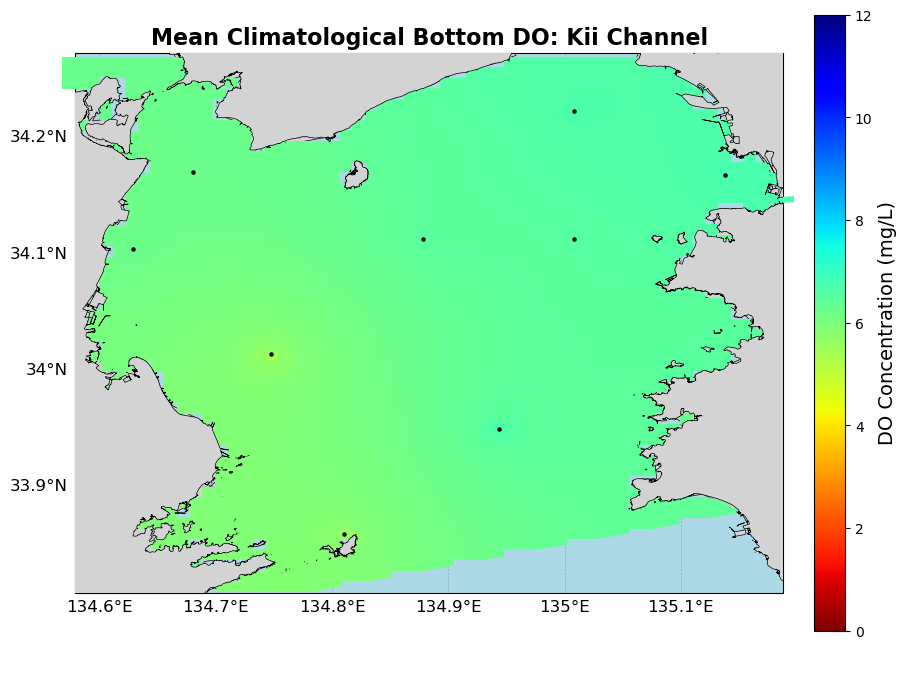

Processing Yearly Mean DO for Aki Nada...


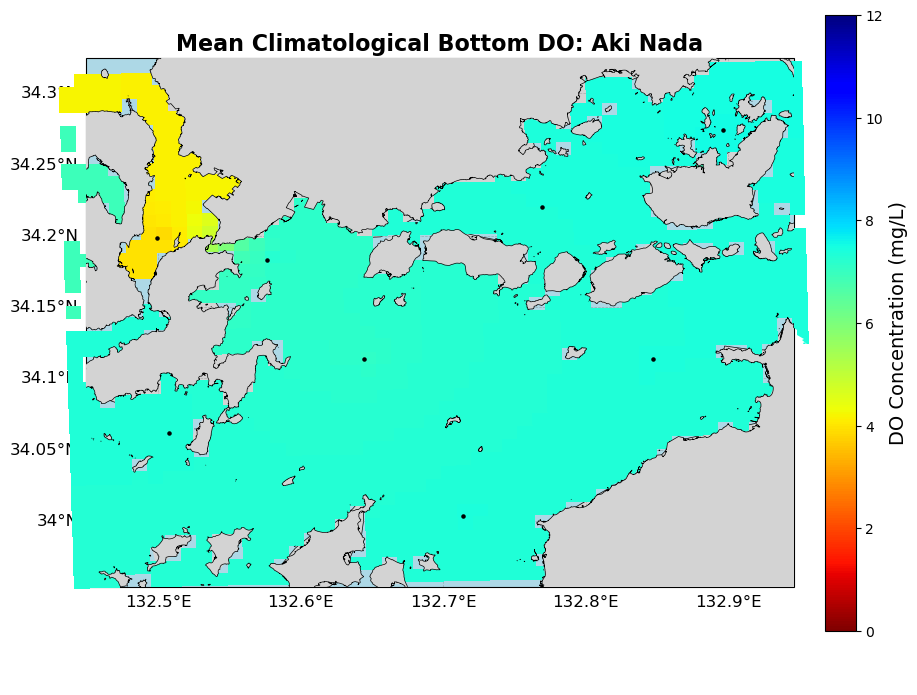

Processing Yearly Mean DO for Hiroshima Bay...


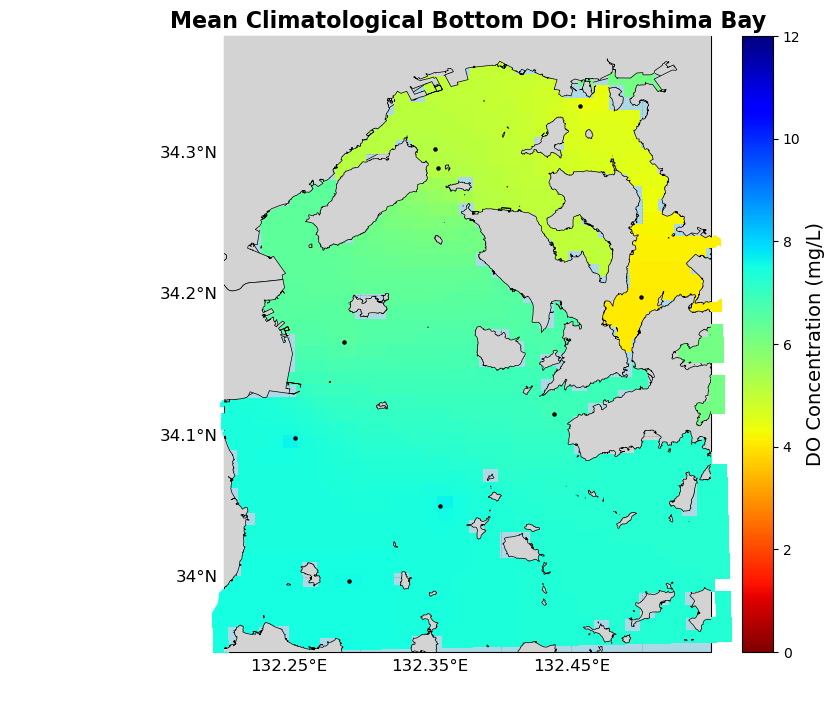

Processing Yearly Mean DO for Hiuchi Nada...


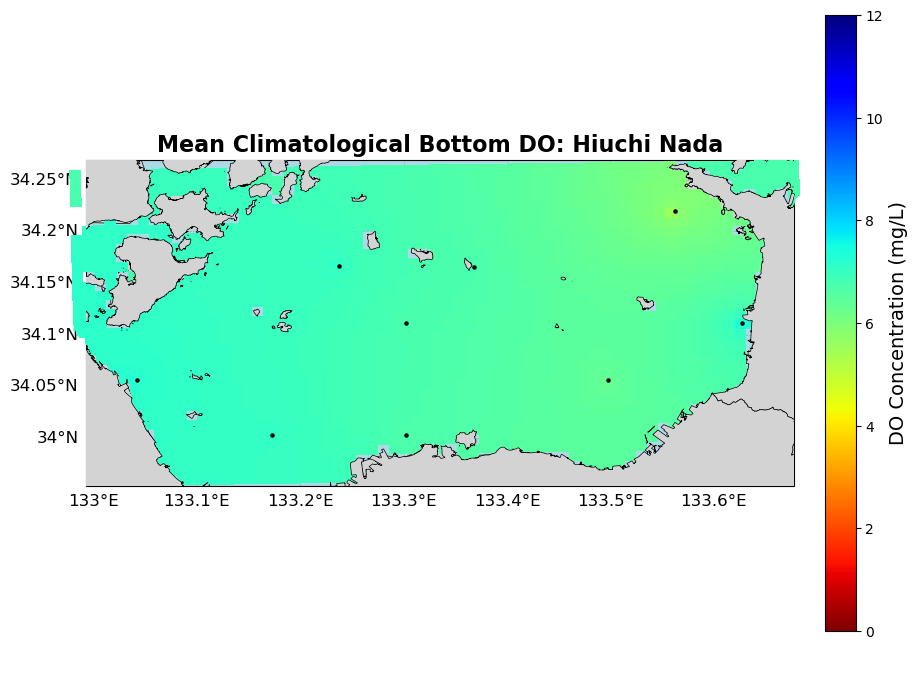

In [4]:
var_cfg = MappingConfig.get_var_settings('do_')
vmin, vmax = var_cfg['vmin'], var_cfg['vmax']
cmap = var_cfg['cmap']
label = var_cfg['label']

for region in regions_info:
    name = region['name']
    df = region['data']
    if df.empty:
        continue
    
    print(f"Processing Yearly Mean DO for {name}...")
    
    # Calculate station-wise multi-year mean DO
    station_mean = df.groupby('zettaicode')[['do_', 'longitude', 'latitude']].mean()
    if station_mean.empty:
        continue
        
    data_bounds = [station_mean['longitude'].min(), station_mean['latitude'].min(), 
                   station_mean['longitude'].max(), station_mean['latitude'].max()]
                   
    grid_info = setup_diffusion_grid(region['water_mask'], data_bounds)
    if grid_info is None:
        print(f"Could not setup grid for {name}")
        continue
        
    # Convert station coords to UTM
    stations_gdf = gpd.GeoDataFrame(
        station_mean,
        geometry=[Point(xy) for xy in zip(station_mean.longitude, station_mean.latitude)],
        crs='EPSG:4326'
    ).to_crs(grid_info['utm_crs'])
    
    pts_x = stations_gdf.geometry.x.values
    pts_y = stations_gdf.geometry.y.values
    do_vals = stations_gdf['do_'].values
    
    # Run interpolation
    Z = run_diffusion_interpolation(do_vals, pts_x, pts_y, grid_info)
    
    # Plotting
    land_boundary = gpd.read_file(region['land_boundary'])
    if land_boundary.crs != "EPSG:4326":
        land_boundary = land_boundary.to_crs("EPSG:4326")
    land_patches_data = build_land_patches(land_boundary, MappingConfig.COLOR_LAND, MappingConfig.COLOR_LAND_EDGE, MappingConfig.LINEWIDTH_LAND)
    
    fig, ax = plt.subplots(1, 1, figsize=(10, 8), subplot_kw={'projection': ccrs.PlateCarree()})
    ax.set_facecolor(MappingConfig.COLOR_OCEAN)
    add_land_to_ax(ax, land_patches_data)
    ax.set_extent(grid_info['extent'], crs=ccrs.PlateCarree())

    c_m = ax.pcolormesh(grid_info['lon_wgs'], grid_info['lat_wgs'], Z,
                        transform=ccrs.PlateCarree(),
                        cmap=cmap, shading='nearest',
                        zorder=MappingConfig.ZORDER_PREDICTED,
                        vmin=vmin, vmax=vmax)

    water_boundary = gpd.read_file(region['water_mask'])
    if water_boundary.crs != "EPSG:4326":
        water_boundary = water_boundary.to_crs("EPSG:4326")
    clip_path = gdf_to_clip_path(water_boundary, ax)
    clip_patch = PathPatch(clip_path, transform=ax.transData)
    c_m.set_clip_path(clip_patch)

    # Plot stations
    ax.scatter(station_mean['longitude'], station_mean['latitude'], c='black', s=5, zorder=MappingConfig.ZORDER_OBSERVATIONS, transform=ccrs.PlateCarree())

    ax.set_title(f'Mean Climatological Bottom DO: {name}', fontsize=16)
    
    gl = ax.gridlines(draw_labels=True, linestyle=MappingConfig.GRID_LINESTYLE,
                      color=MappingConfig.GRID_COLOR, alpha=MappingConfig.GRID_ALPHA,
                      linewidth=MappingConfig.GRID_LINEWIDTH, zorder=MappingConfig.ZORDER_GRIDLINES)
    gl.top_labels = False
    gl.right_labels = False
    
    cbar = fig.colorbar(c_m, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label(label, fontsize=14)
    MappingConfig.format_colorbar_ticks(cbar, 'do_')

    plt.show()

## 2. Frequency Maps: Hypoxic (0-2 mg/L) vs. Low DO (2-5 mg/L)

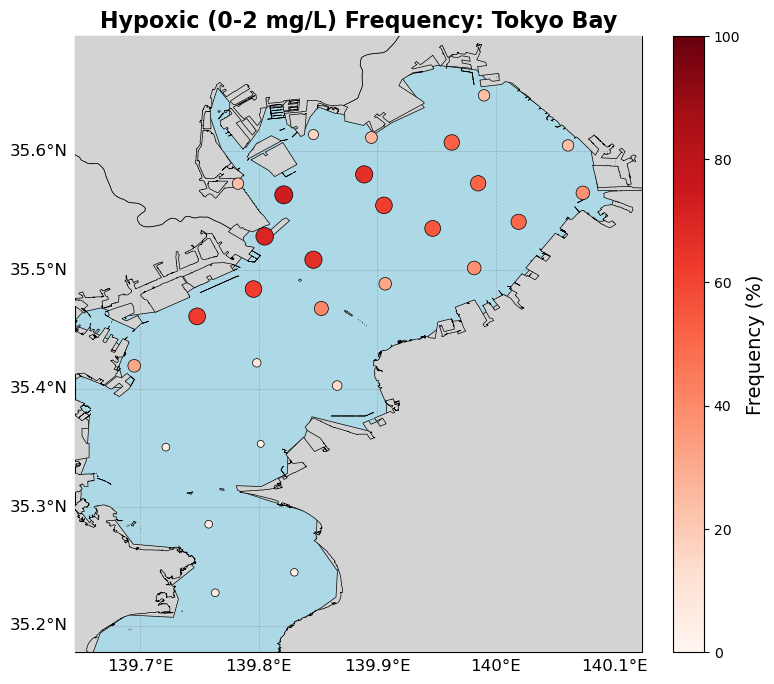

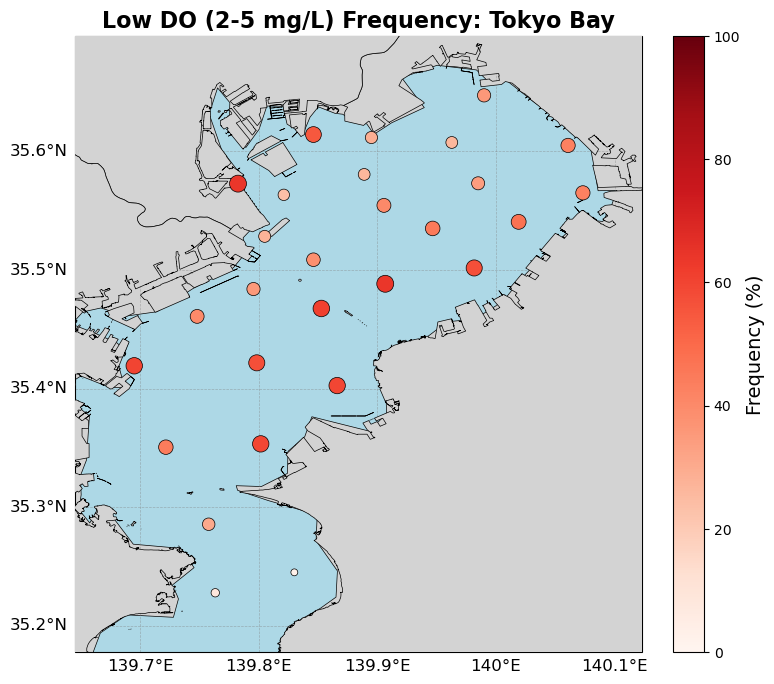

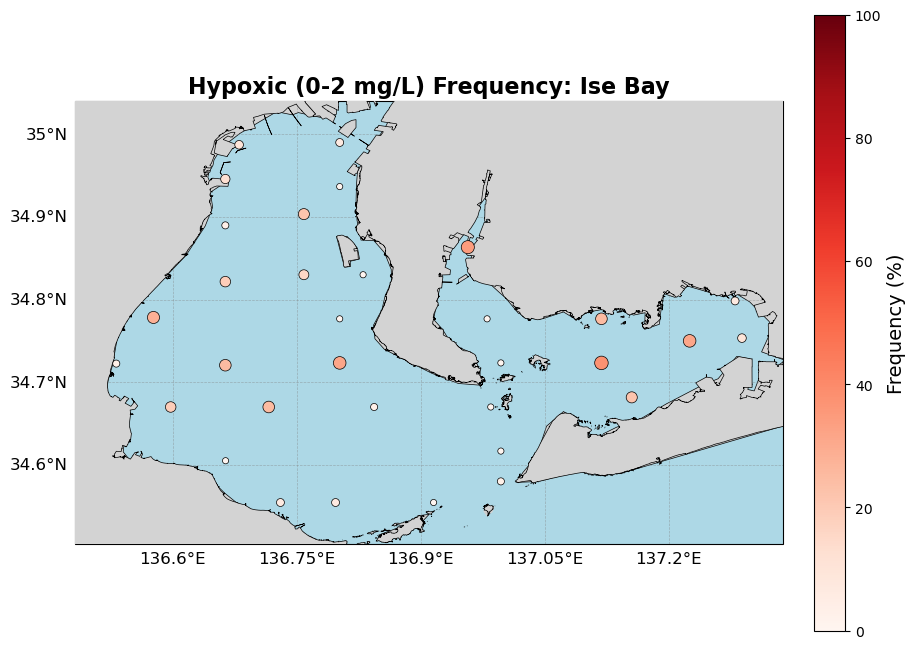

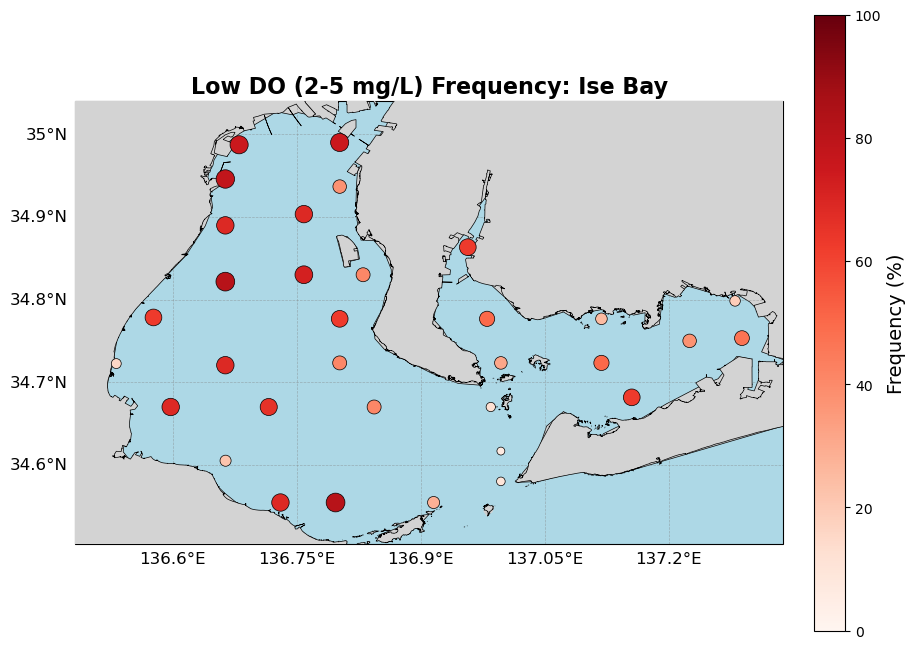

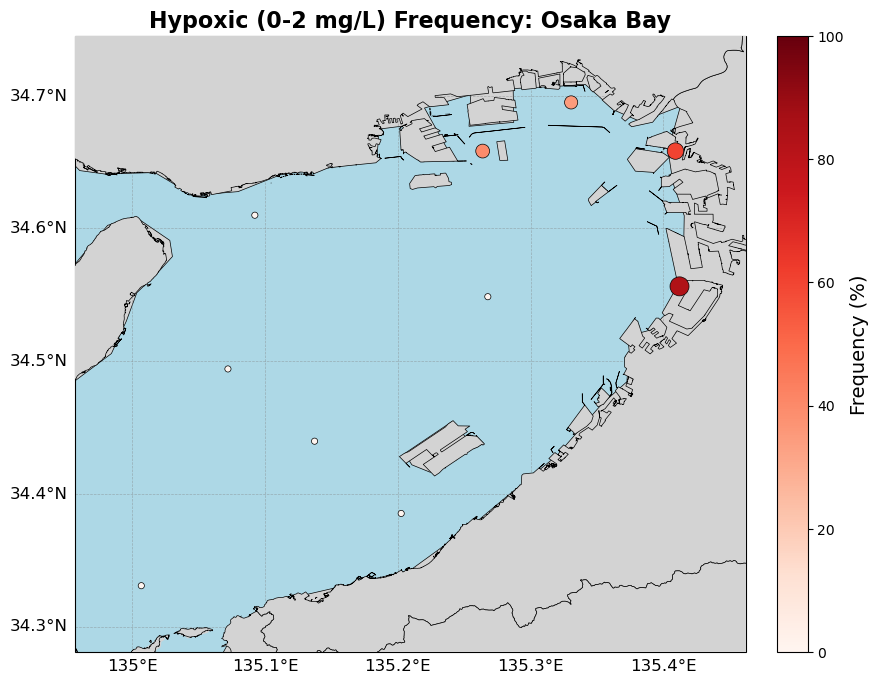

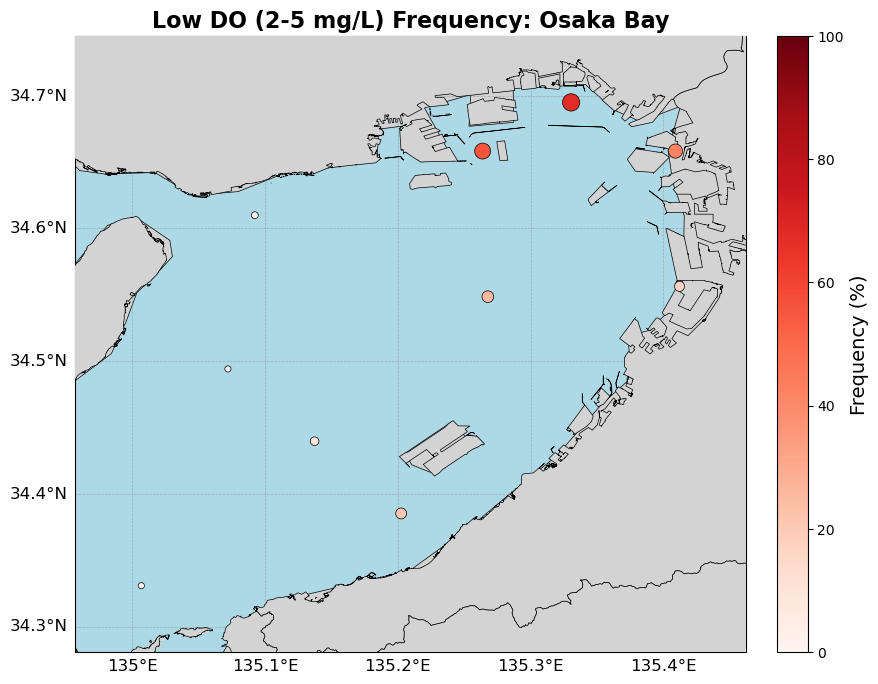

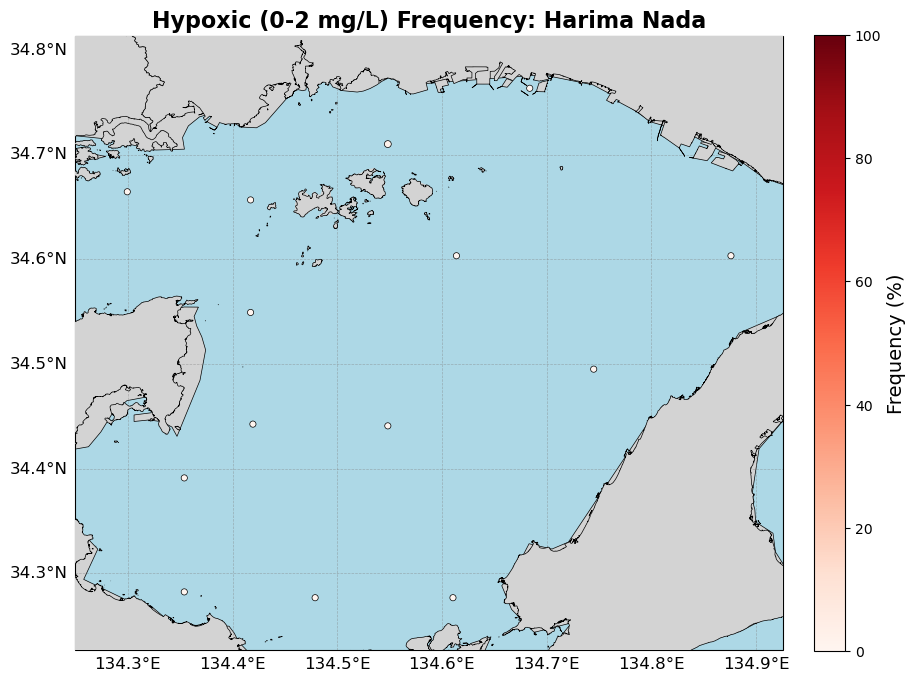

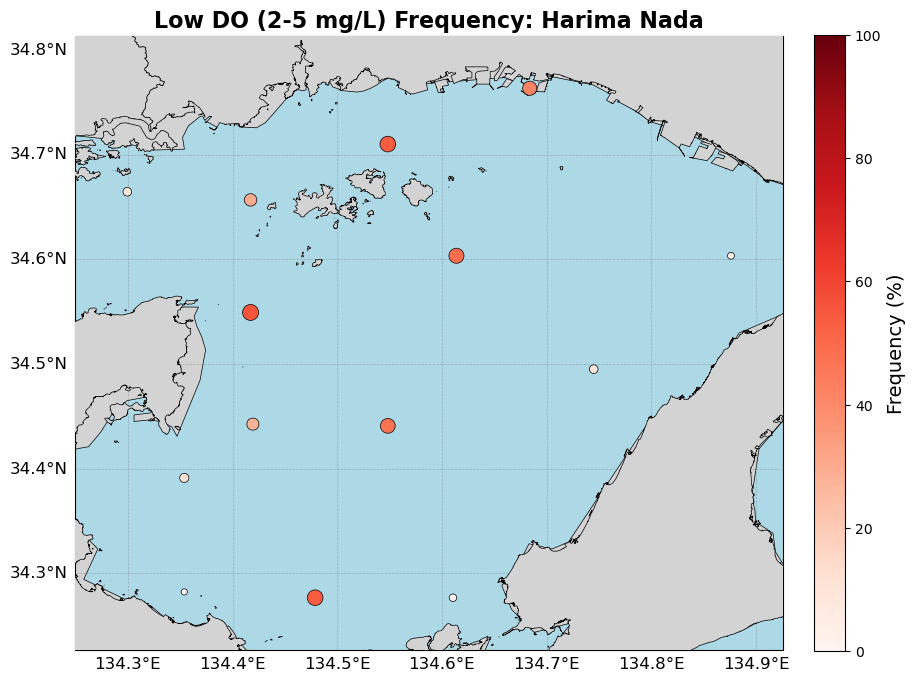

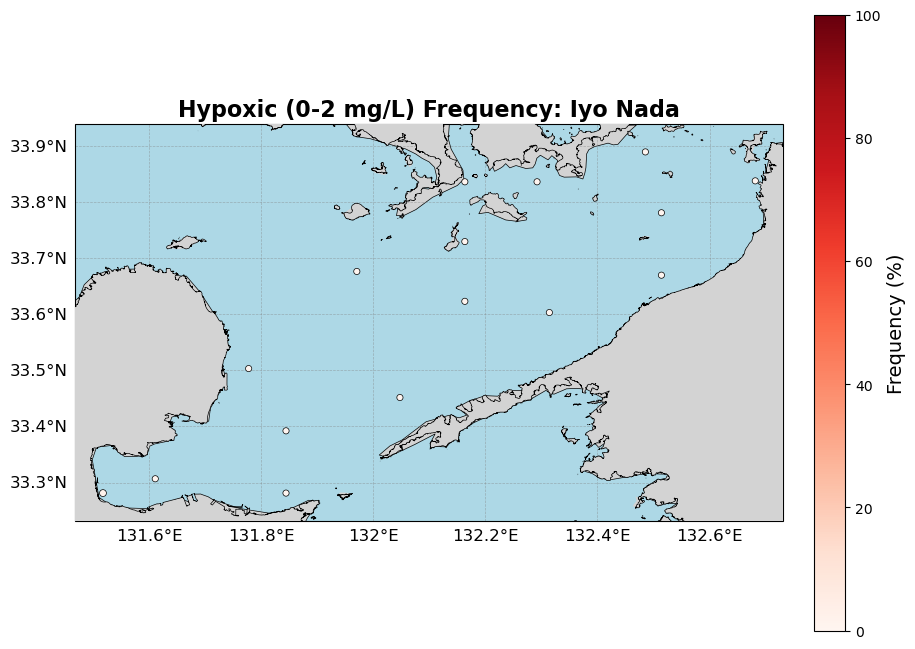

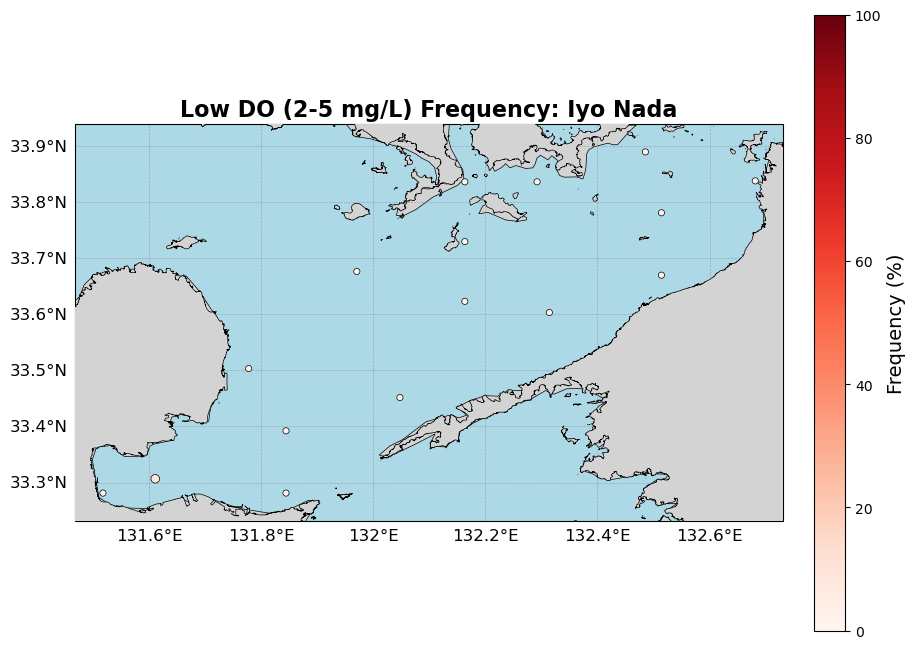

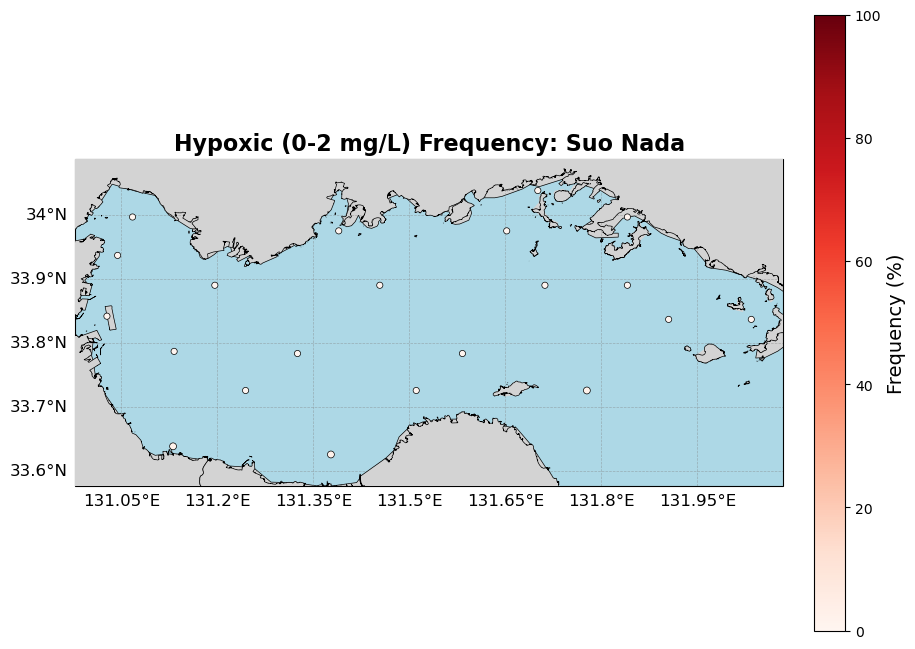

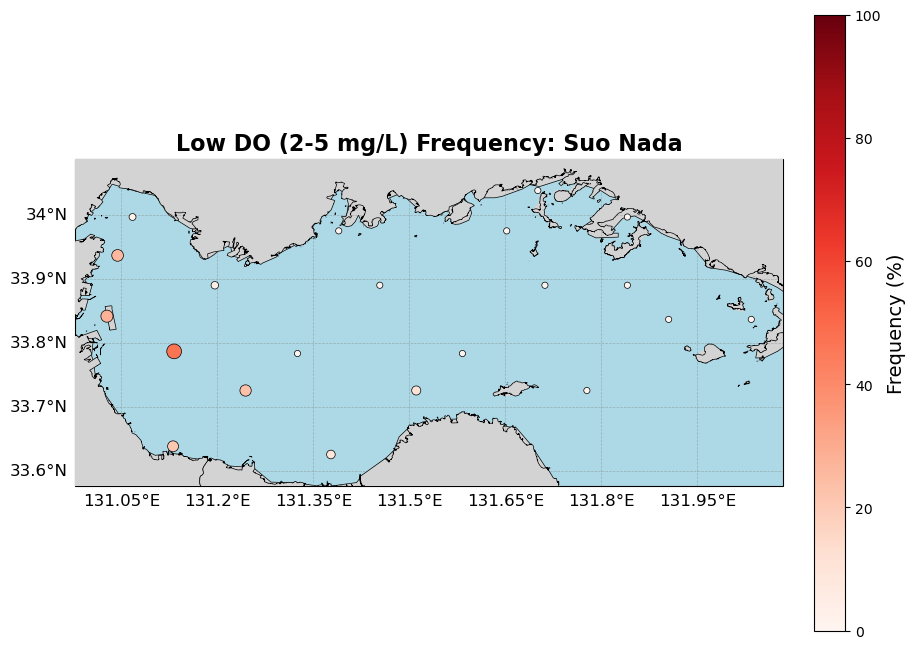

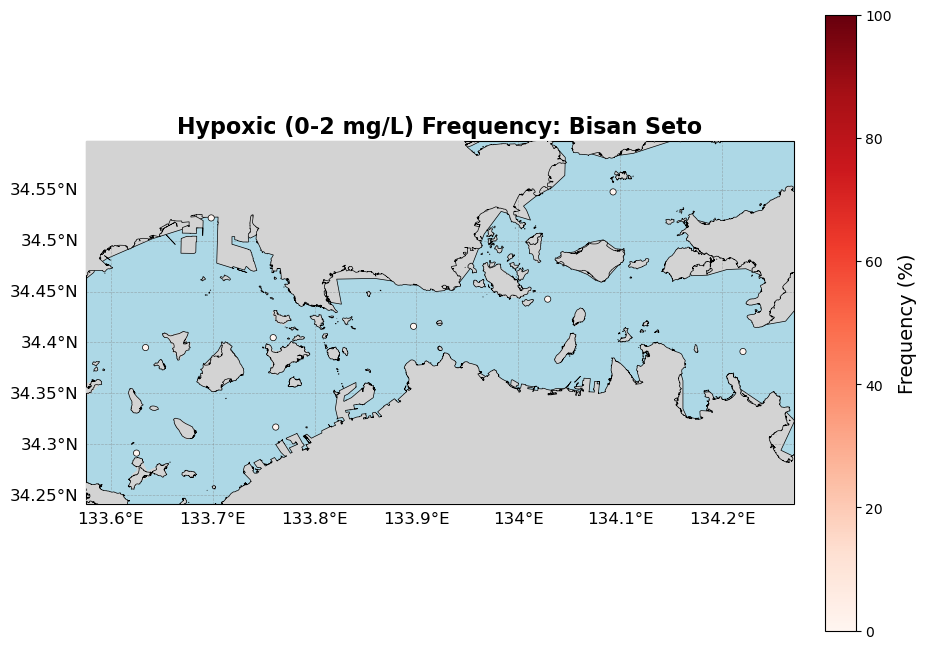

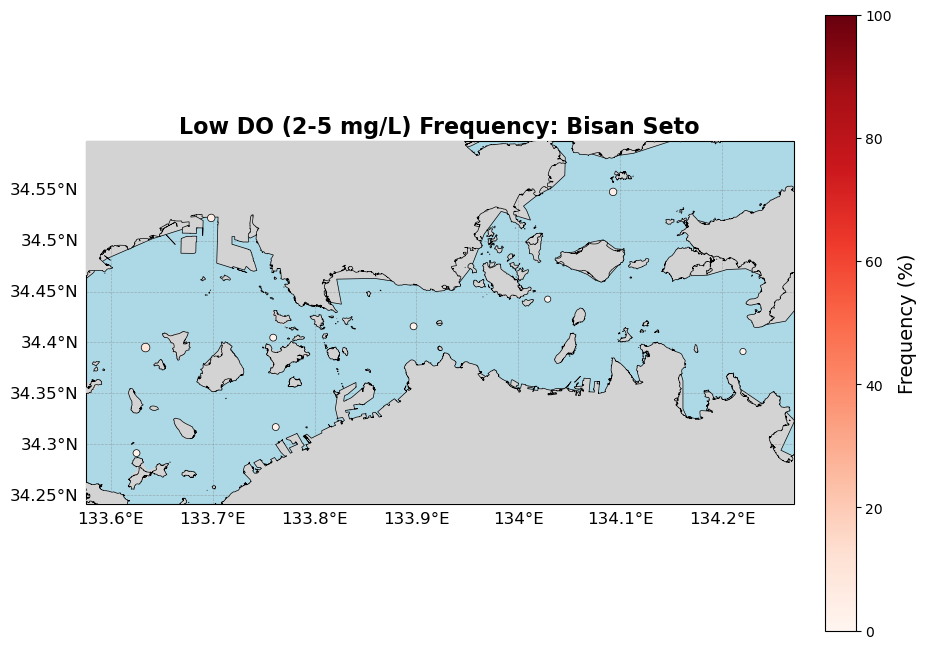

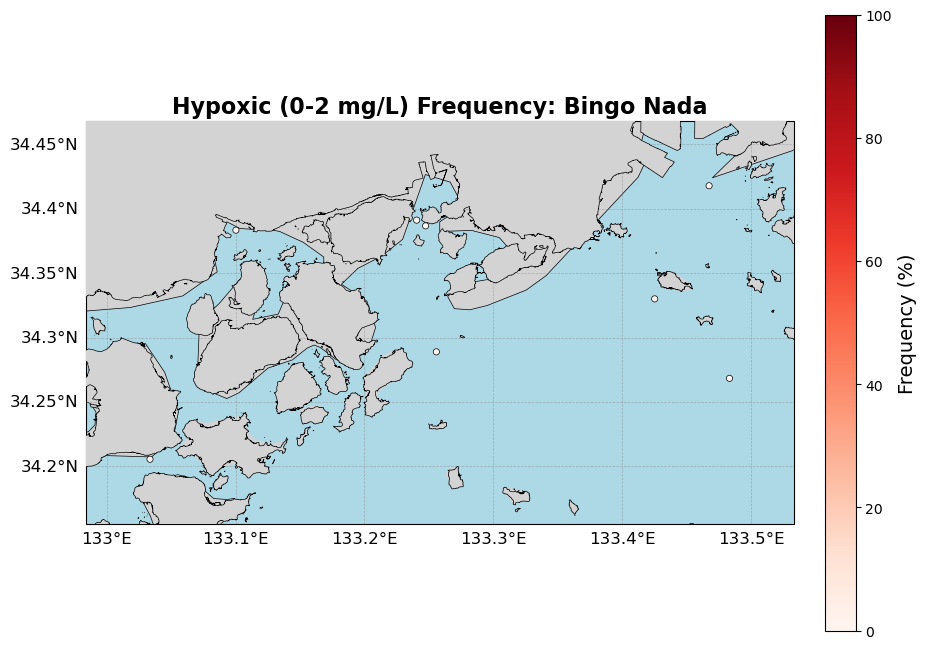

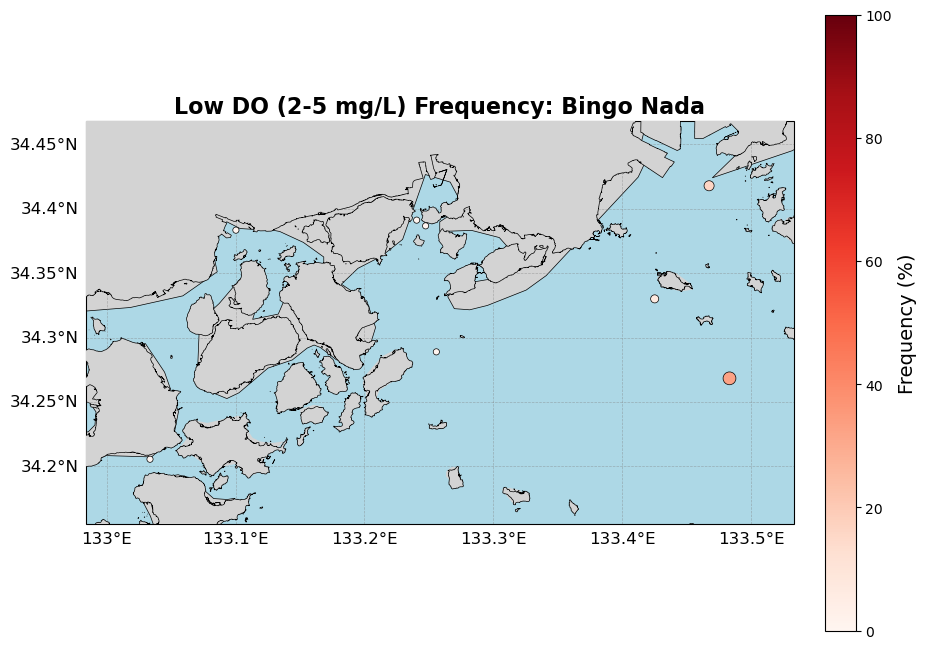

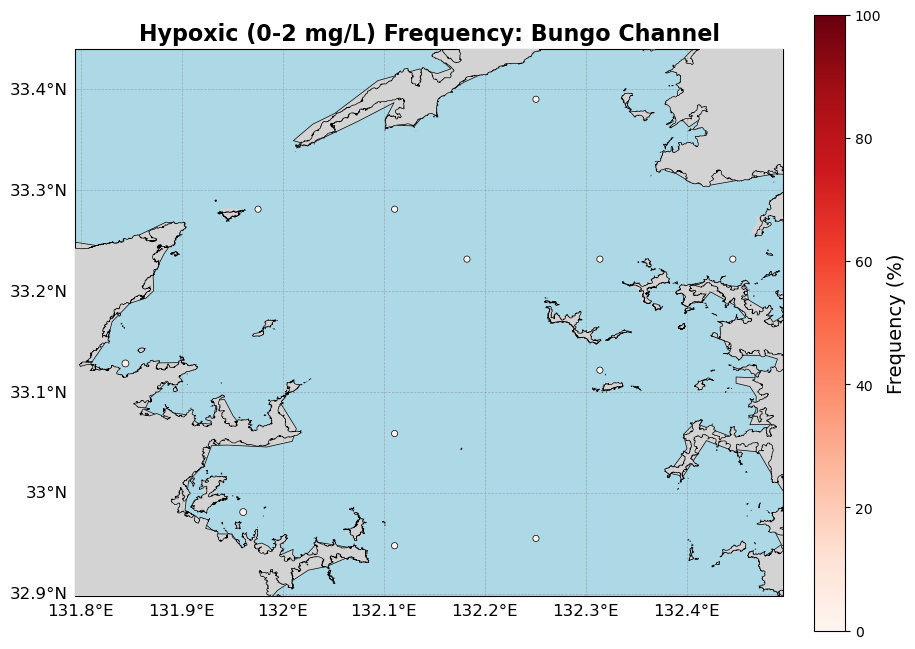

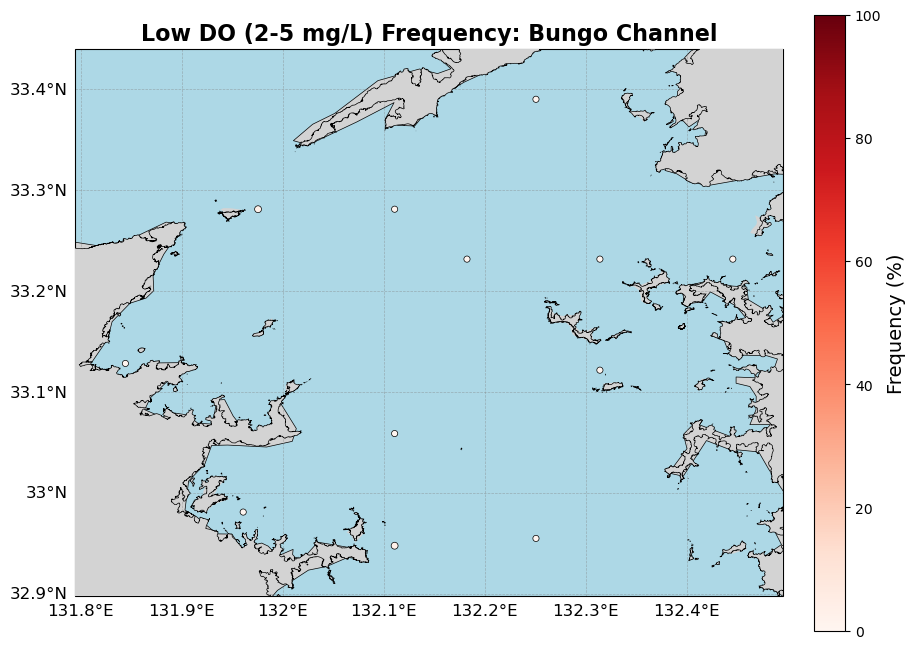

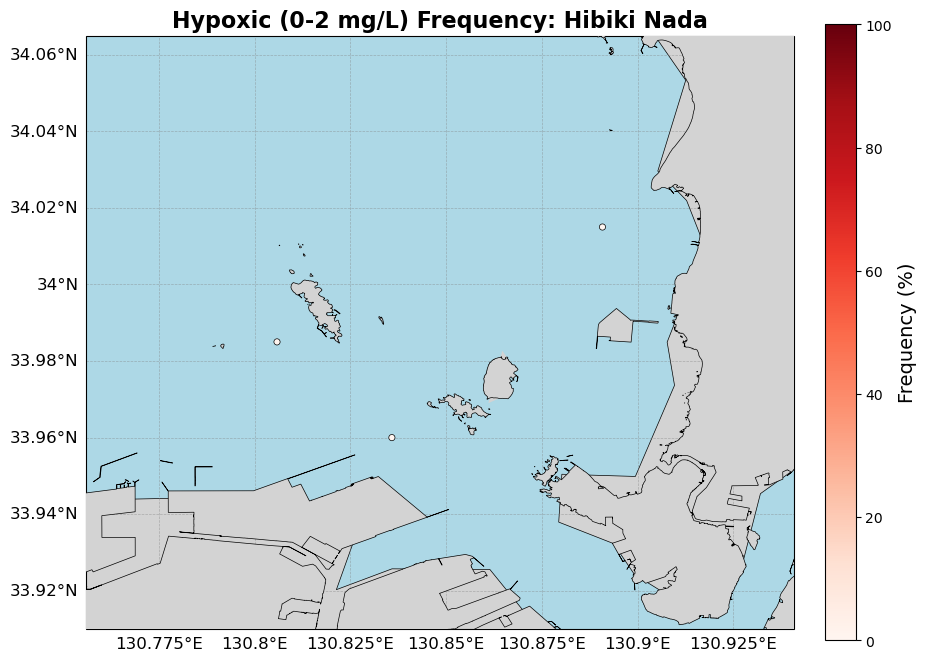

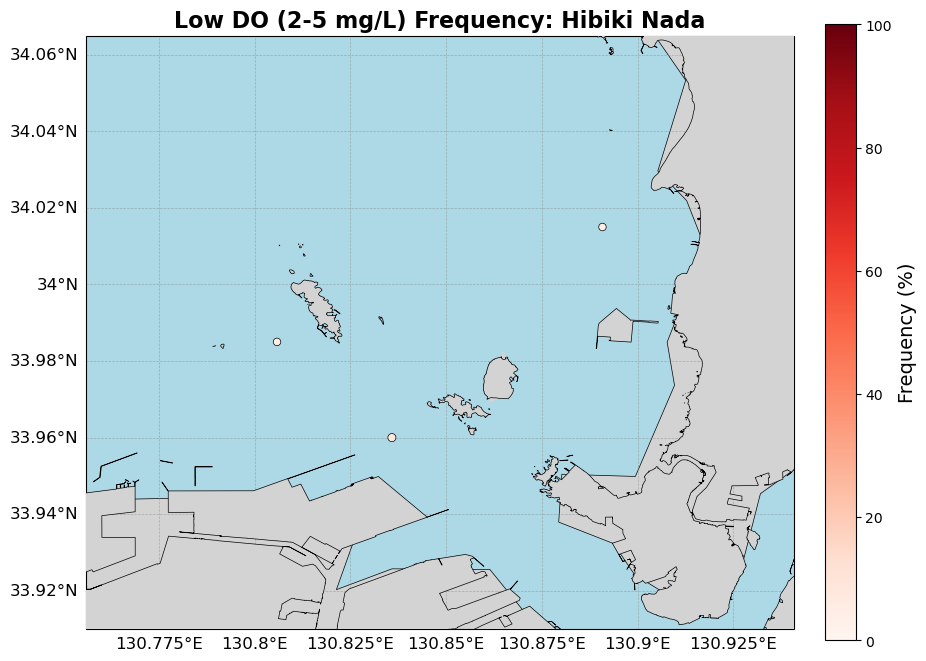

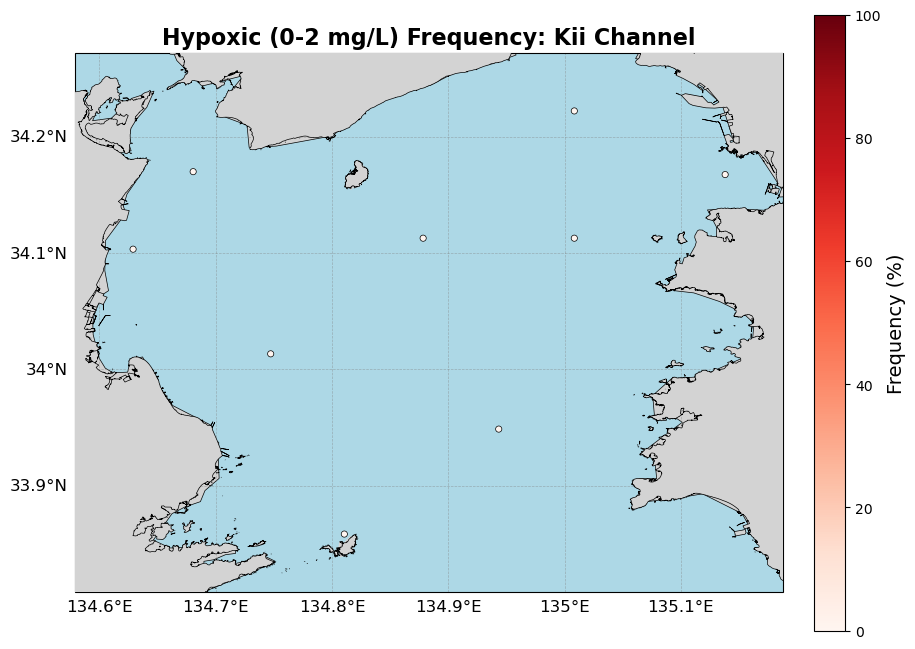

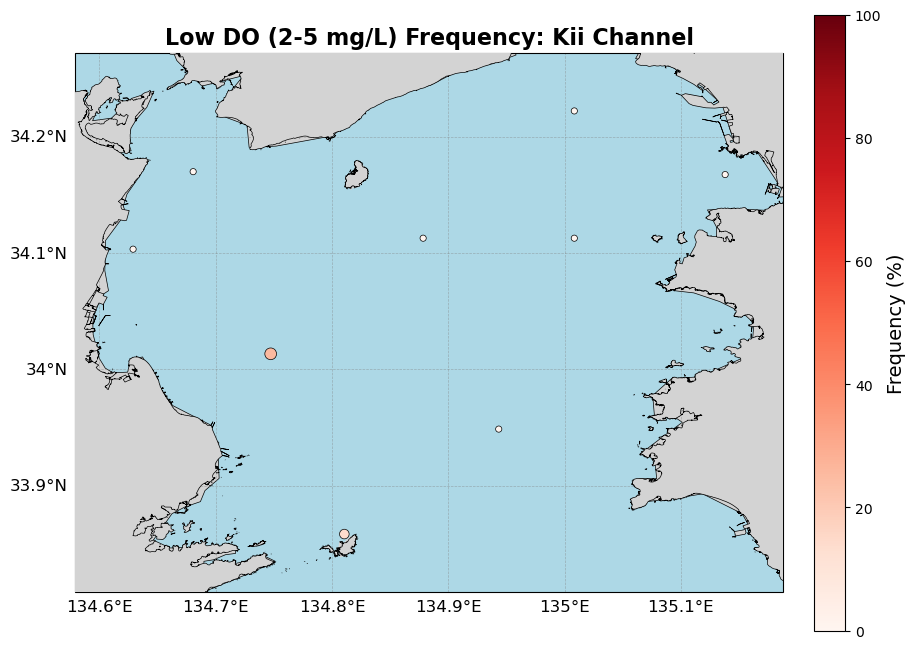

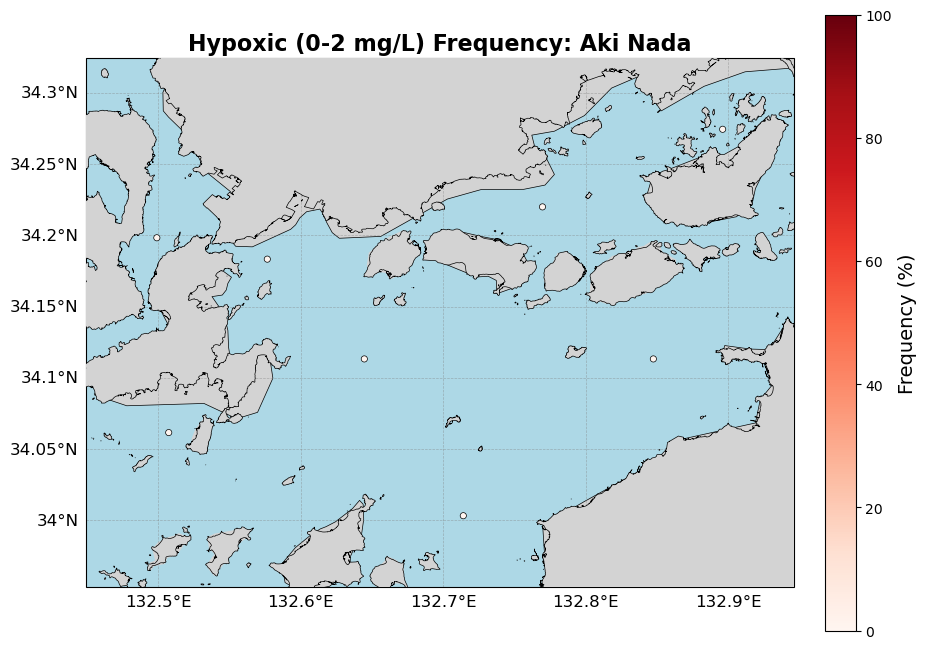

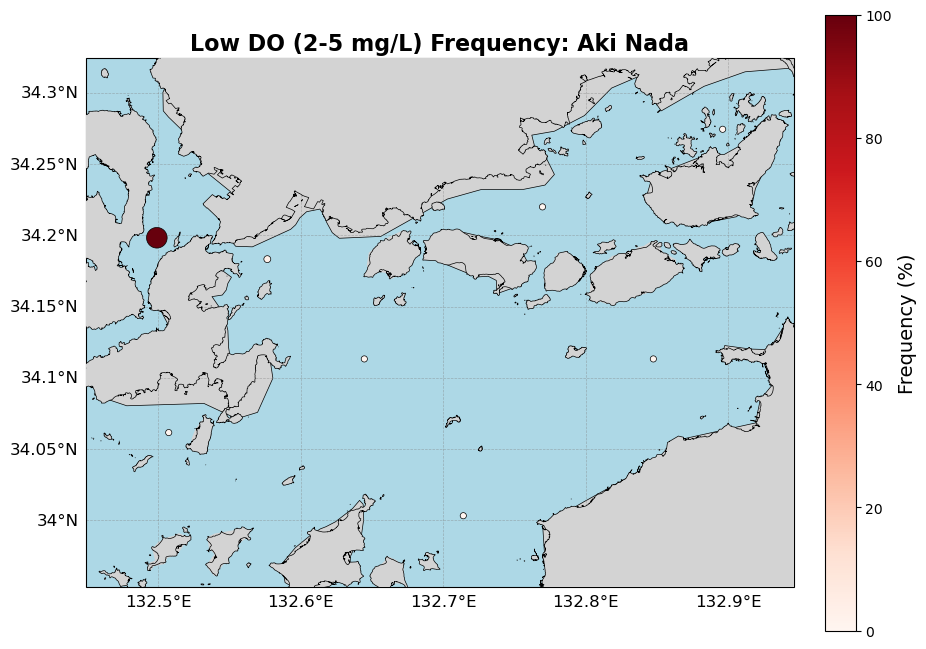

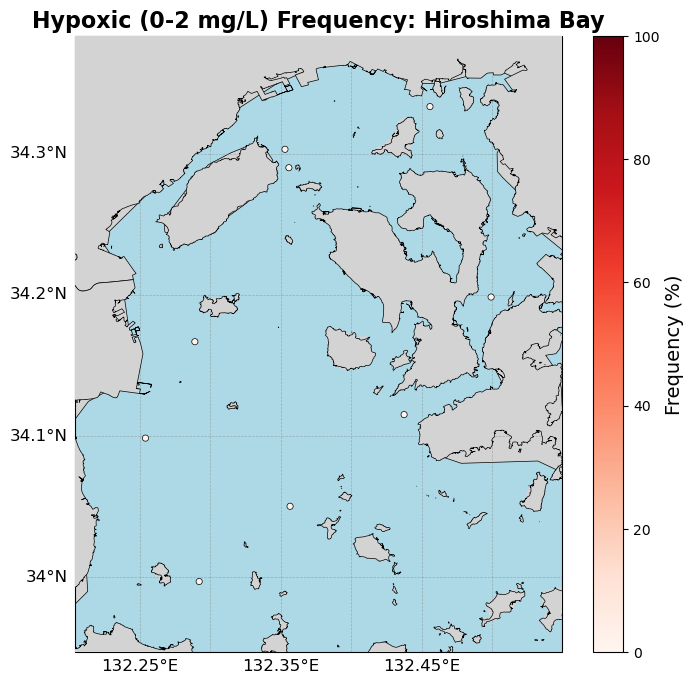

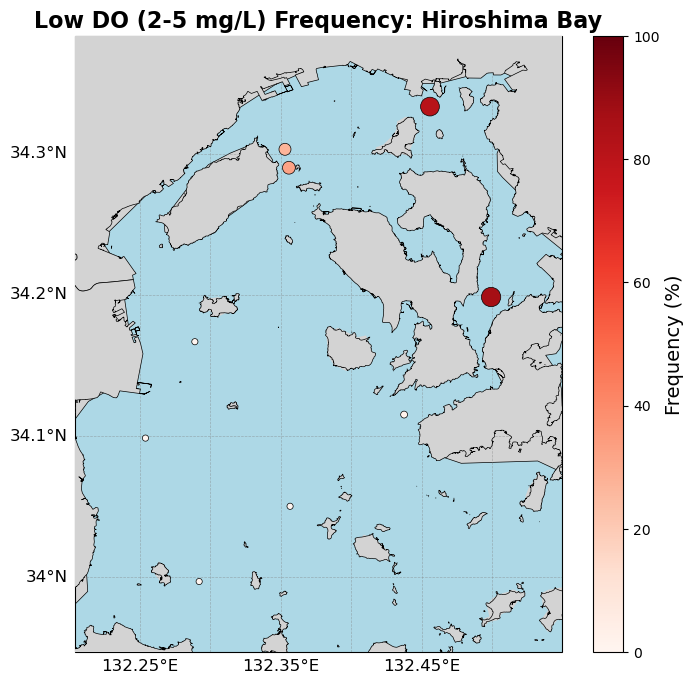

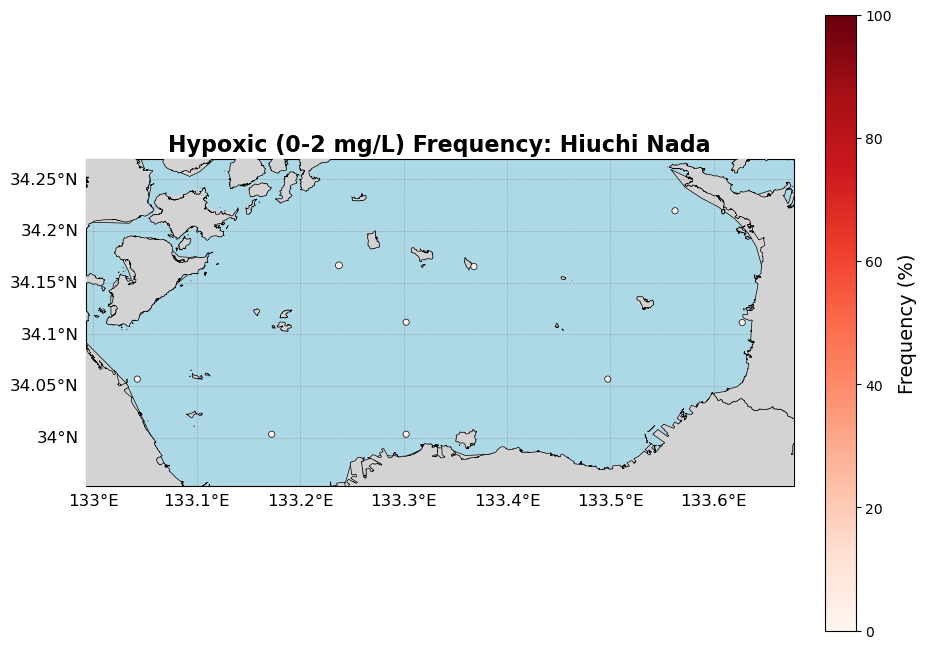

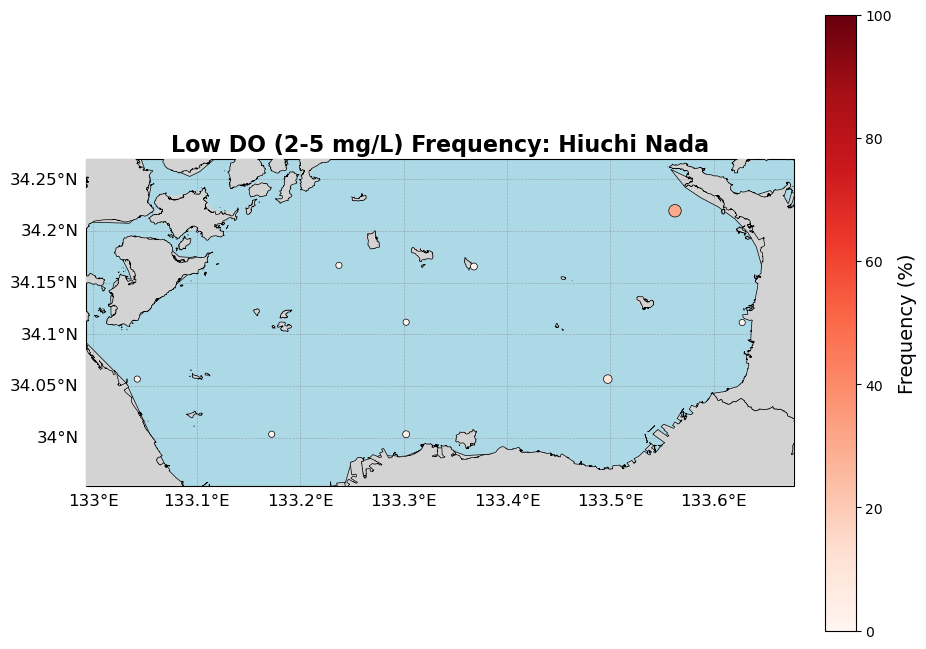

In [5]:
def plot_frequency_map(region_name, df, land_boundary_path, extent, threshold_min, threshold_max, title):
    # Calculate frequency
    def calc_freq(group):
        total_years = group['year'].nunique()
        condition_years = group[(group['do_'] >= threshold_min) & (group['do_'] <= threshold_max)]['year'].nunique()
        return (condition_years / total_years) * 100

    freq_df = df.groupby(['zettaicode', 'longitude', 'latitude']).apply(calc_freq).reset_index(name='frequency')
    
    land_boundary = gpd.read_file(land_boundary_path)
    if land_boundary.crs != "EPSG:4326":
        land_boundary = land_boundary.to_crs("EPSG:4326")
    land_patches_data = build_land_patches(land_boundary, MappingConfig.COLOR_LAND, MappingConfig.COLOR_LAND_EDGE, MappingConfig.LINEWIDTH_LAND)
    
    fig, ax = plt.subplots(1, 1, figsize=(10, 8), subplot_kw={'projection': ccrs.PlateCarree()})
    ax.set_facecolor(MappingConfig.COLOR_OCEAN)
    add_land_to_ax(ax, land_patches_data)
    ax.set_extent(extent, crs=ccrs.PlateCarree())
    
    sc = ax.scatter(freq_df['longitude'], freq_df['latitude'], 
                    c=freq_df['frequency'], cmap='Reds', vmin=0, vmax=100,
                    s=freq_df['frequency']*2 + 20, edgecolor='k', linewidth=0.5,
                    transform=ccrs.PlateCarree(), zorder=MappingConfig.ZORDER_OBSERVATIONS)
    
    ax.set_title(f'{title}: {region_name}', fontsize=16)
    gl = ax.gridlines(draw_labels=True, linestyle=MappingConfig.GRID_LINESTYLE,
                      color=MappingConfig.GRID_COLOR, alpha=MappingConfig.GRID_ALPHA,
                      linewidth=MappingConfig.GRID_LINEWIDTH, zorder=MappingConfig.ZORDER_GRIDLINES)
    gl.top_labels = False
    gl.right_labels = False
    
    cbar = fig.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label('Frequency (%)', fontsize=14)
    plt.show()

for region in regions_info:
    name = region['name']
    df = region['data']
    if df.empty:
        continue
    
    data_bounds = [df['longitude'].min(), df['latitude'].min(), df['longitude'].max(), df['latitude'].max()]
    extent = [data_bounds[0]-0.05, data_bounds[2]+0.05, data_bounds[1]-0.05, data_bounds[3]+0.05]
    
    # Hypoxic (0-2)
    plot_frequency_map(name, df, region['land_boundary'], extent, 0.0, 2.0, "Hypoxic (0-2 mg/L) Frequency")
    
    # Low DO (2-5)
    plot_frequency_map(name, df, region['land_boundary'], extent, 2.0, 5.0, "Low DO (2-5 mg/L) Frequency")

## 3. Number of Hypoxic Stations Summary

In [6]:
summary_records = []

for region in regions_info:
    name = region['name']
    df = region['data']
    if df.empty:
        continue
        
    total_stations = df['zettaicode'].nunique()
    
    hypoxic_df = df[(df['do_'] >= 0.0) & (df['do_'] <= 2.0)]
    hypoxic_stations = hypoxic_df['zettaicode'].nunique()
    hypoxic_events = len(hypoxic_df)
    
    lowdo_df = df[(df['do_'] > 2.0) & (df['do_'] <= 5.0)]
    lowdo_stations = lowdo_df['zettaicode'].nunique()
    lowdo_events = len(lowdo_df)
    
    summary_records.append({
        'Region / Basin': name,
        'Total Stations': total_stations,
        'Ever Hypoxic (0-2) Stations': hypoxic_stations,
        'Total Hypoxic Events': hypoxic_events,
        'Ever Low DO (2-5) Stations': lowdo_stations,
        'Total Low DO Events': lowdo_events
    })

summary_df = pd.DataFrame(summary_records)
display(summary_df)

,Region / Basin,Total Stations,Ever Hypoxic (0-2) Stations,Total Hypoxic Events,Ever Low DO (2-5) Stations,Total Low DO Events
0,Tokyo Bay,28,28,429,28,469
1,Ise Bay,33,24,129,33,513
2,Osaka Bay,10,4,94,8,99
3,Harima Nada,14,1,1,13,170
4,Iyo Nada,16,1,1,1,1
5,Suo Nada,21,3,3,9,74
6,Bisan Seto,9,0,0,7,12
7,Bingo Nada,8,0,0,3,24
8,Bungo Channel,12,2,2,2,2
9,Hibiki Nada,3,0,0,3,7


## 4. DO Trend and Severity Spatial Mapping

Processing DO Trend Map for Tokyo Bay...


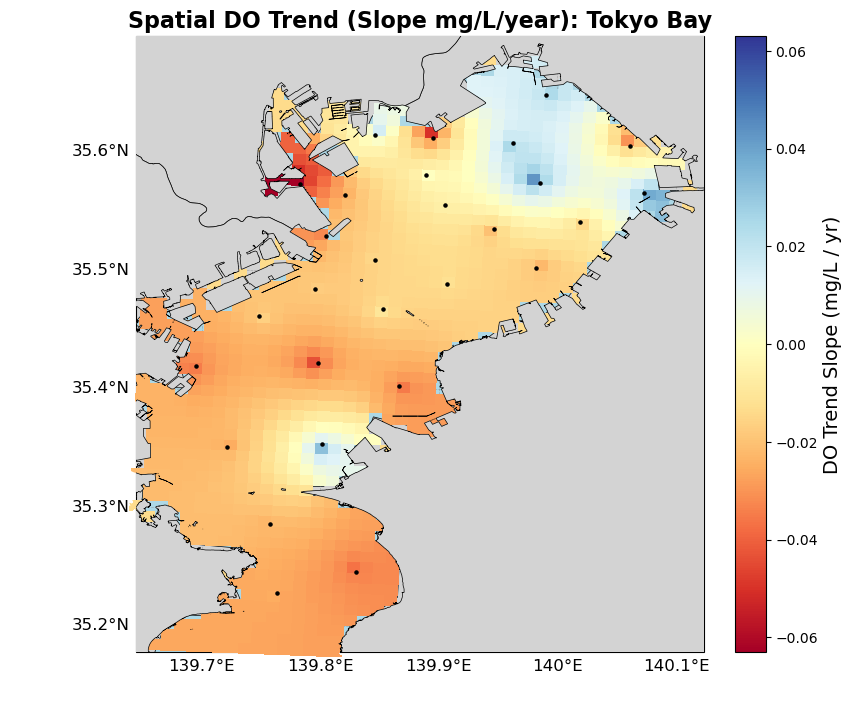

Processing DO Trend Map for Ise Bay...


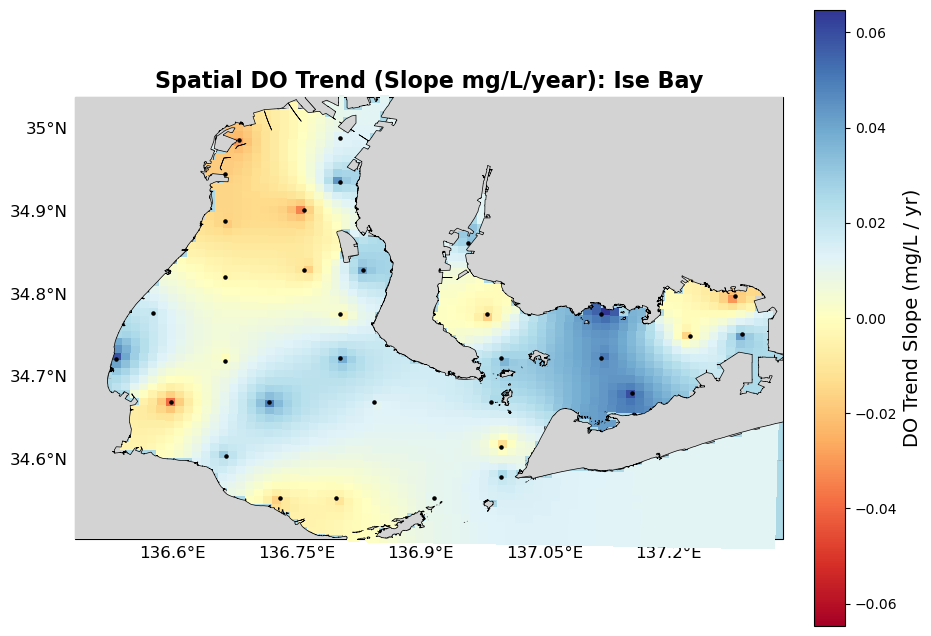

Processing DO Trend Map for Osaka Bay...


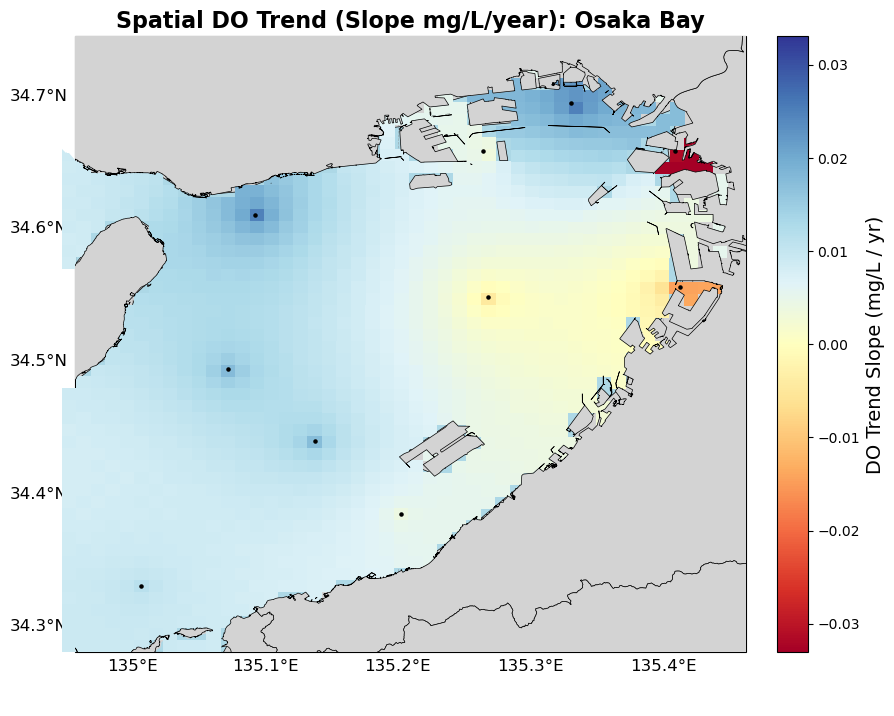

Processing DO Trend Map for Harima Nada...


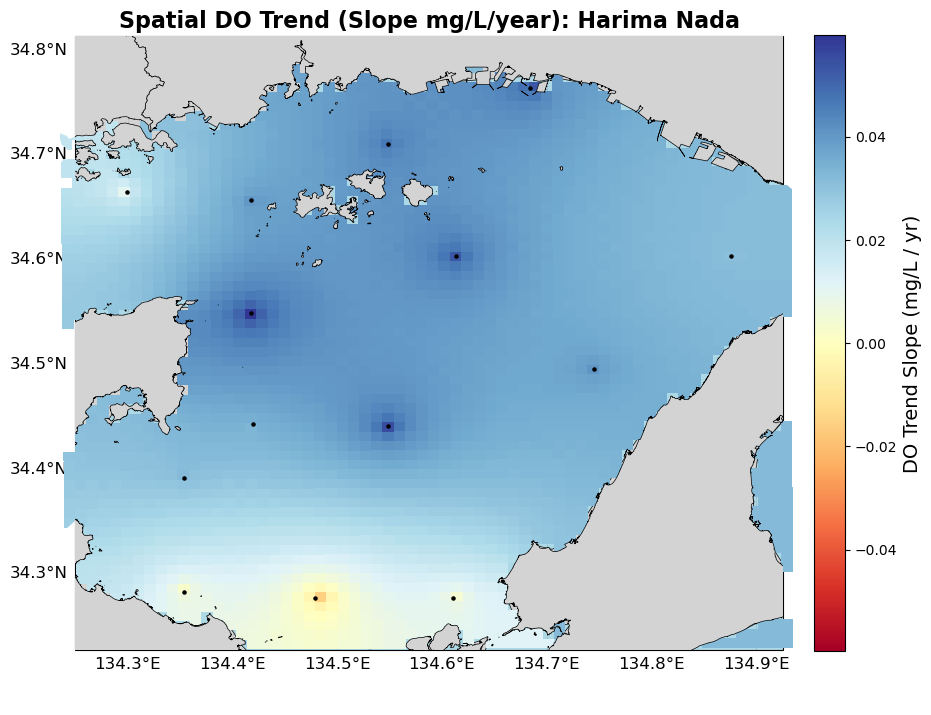

Processing DO Trend Map for Iyo Nada...


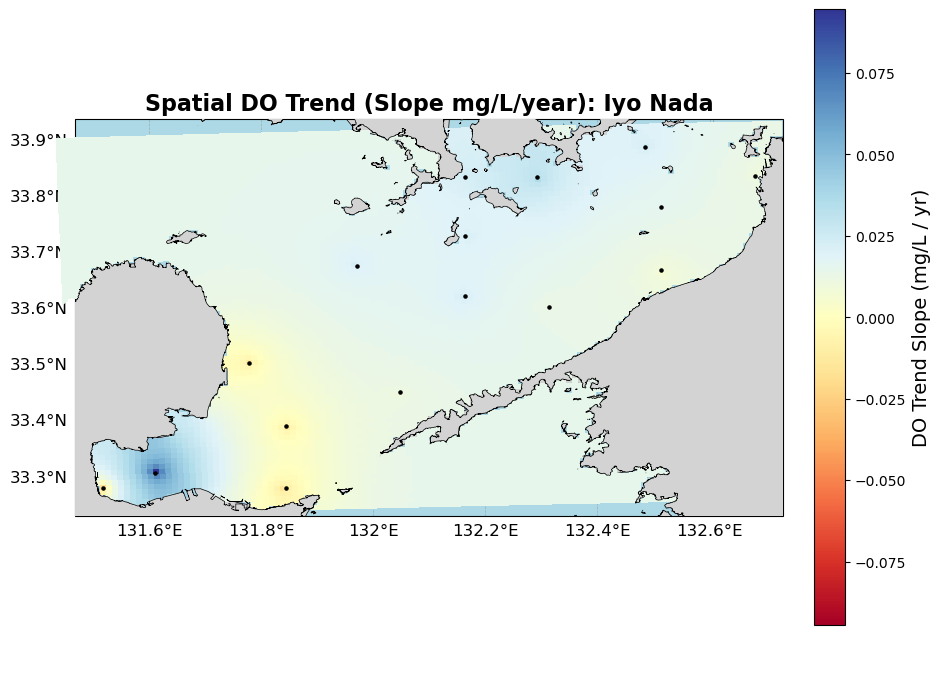

Processing DO Trend Map for Suo Nada...


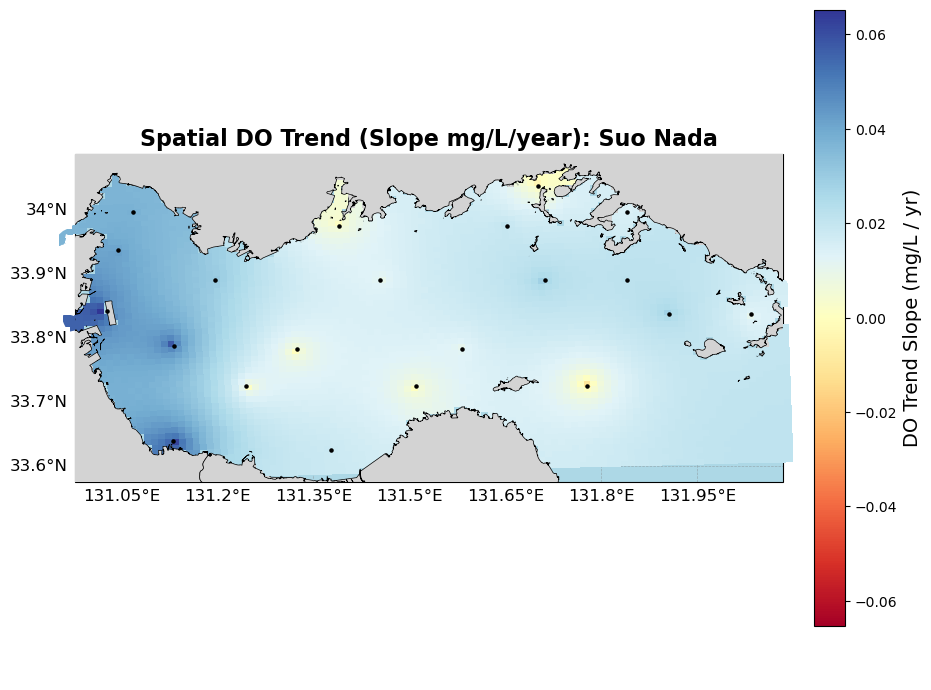

Processing DO Trend Map for Bisan Seto...


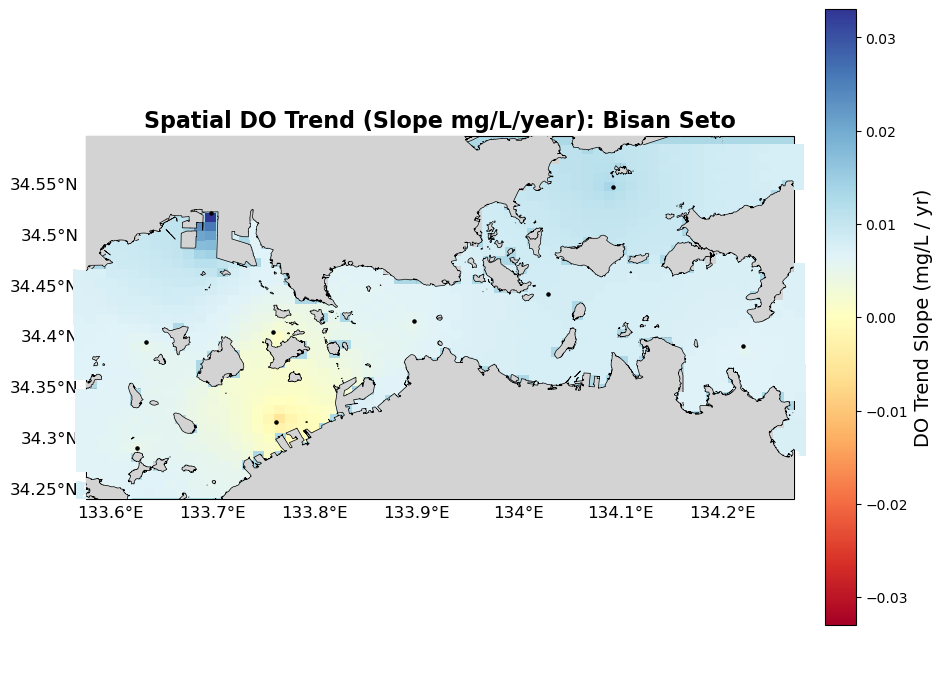

Processing DO Trend Map for Bingo Nada...


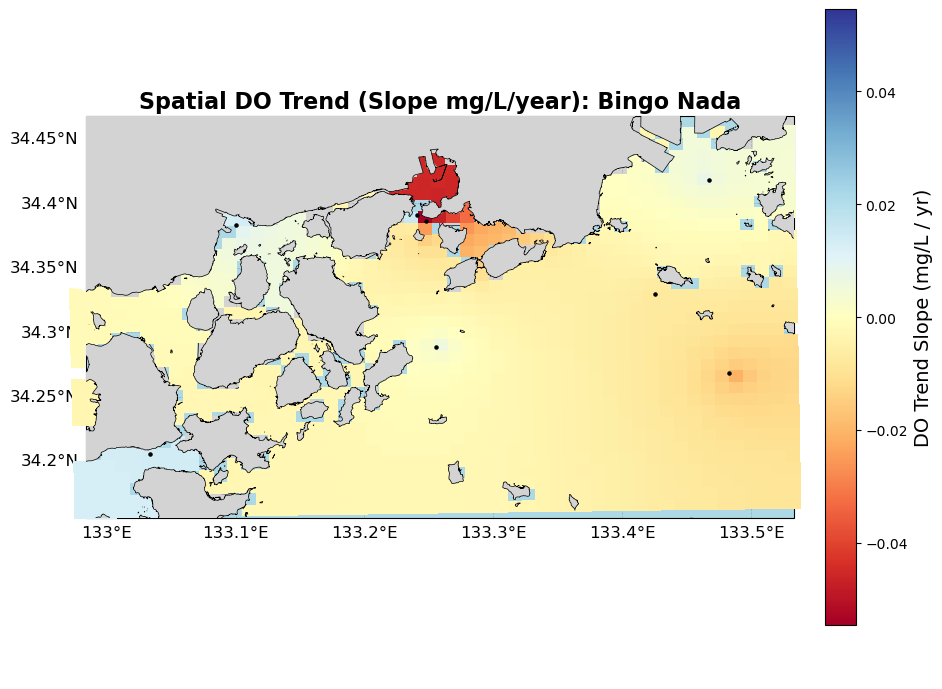

Processing DO Trend Map for Bungo Channel...


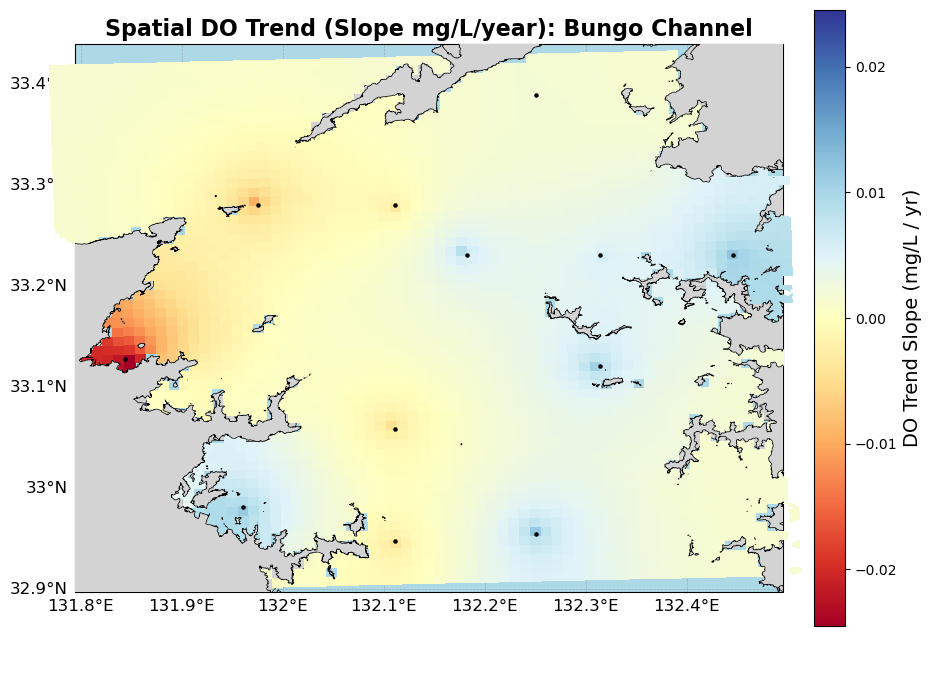

Processing DO Trend Map for Hibiki Nada...


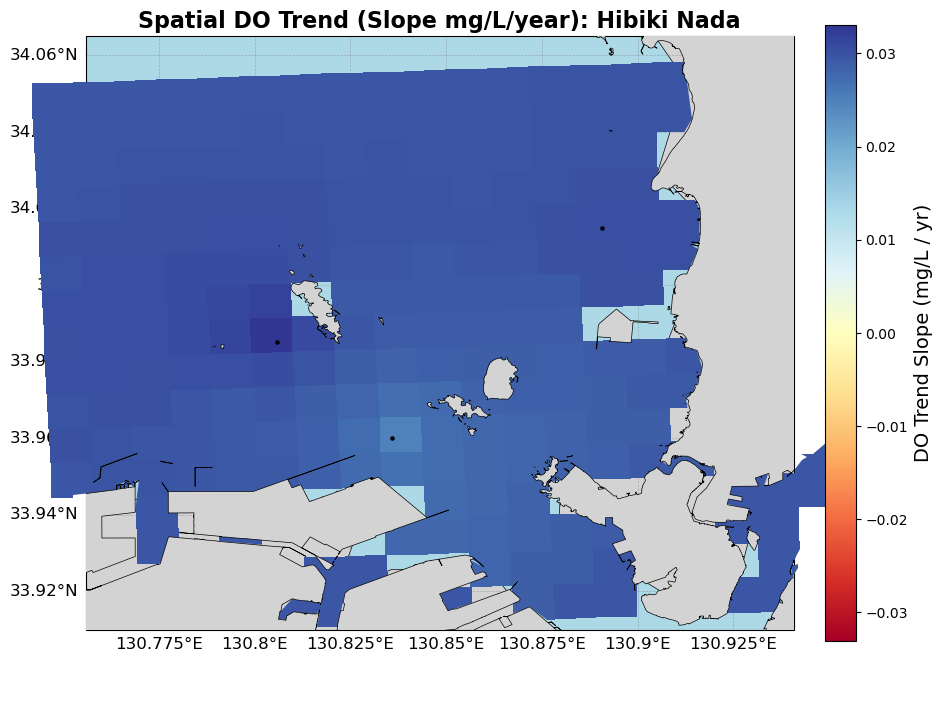

Processing DO Trend Map for Kii Channel...


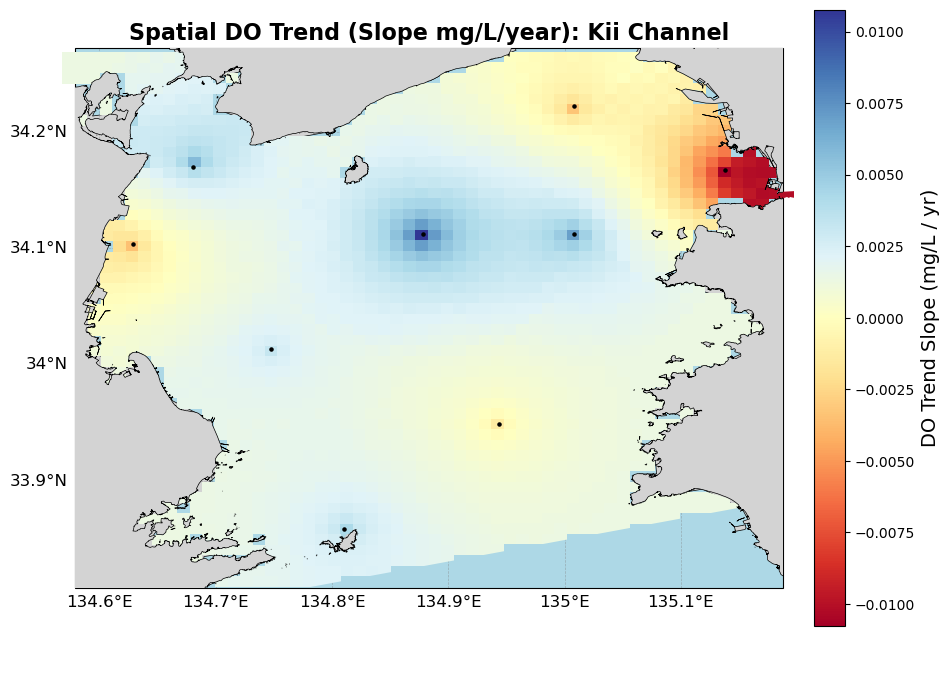

Processing DO Trend Map for Aki Nada...


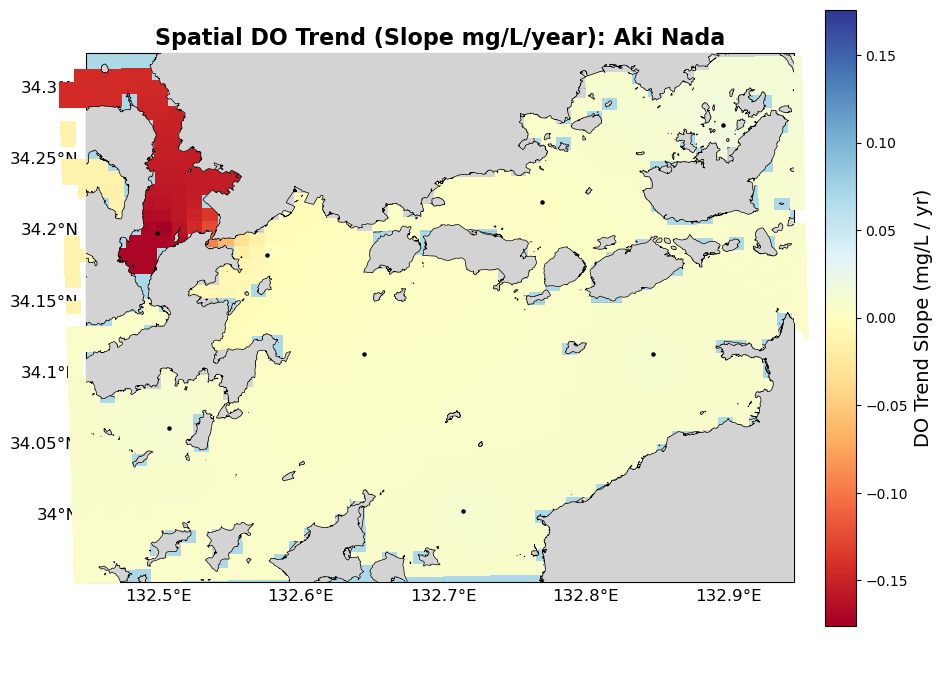

Processing DO Trend Map for Hiroshima Bay...


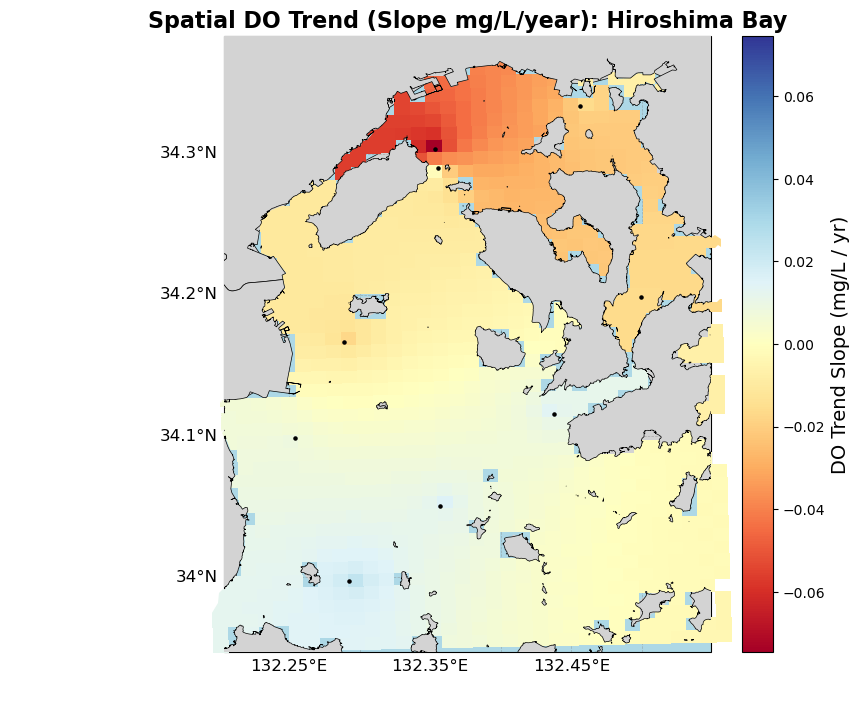

Processing DO Trend Map for Hiuchi Nada...


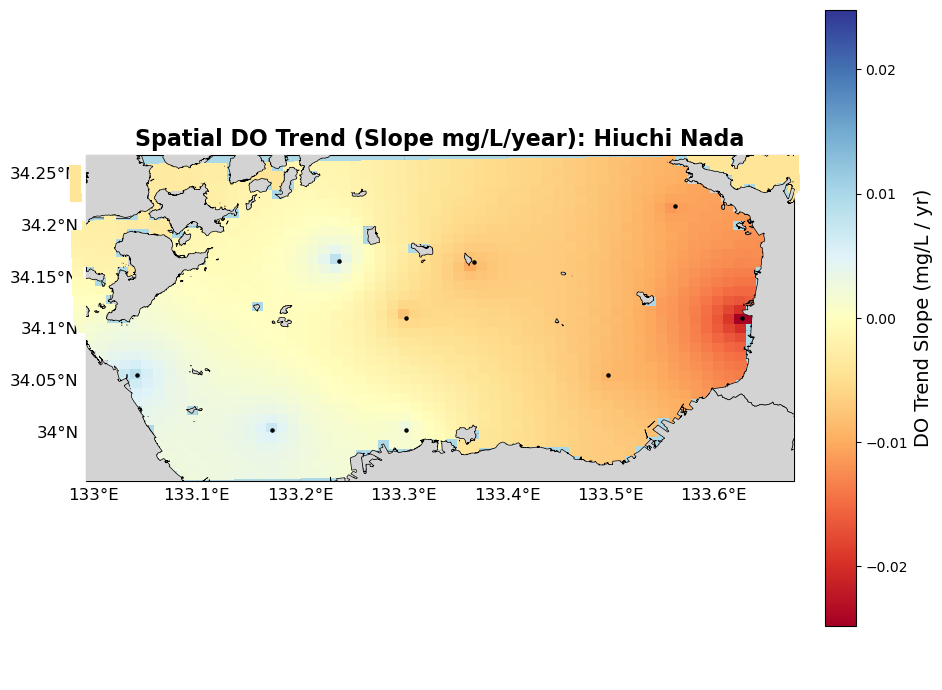

In [7]:
for region in regions_info:
    name = region['name']
    df = region['data']
    if df.empty:
        continue
        
    print(f"Processing DO Trend Map for {name}...")
    
    # Calculate slopes
    slopes = []
    lons = []
    lats = []
    
    for station, group in df.groupby('zettaicode'):
        group = group.dropna(subset=['year', 'do_'])
        if len(group) < 5:  # Require at least 5 years of data
            continue
        slope, intercept, r_value, p_value, std_err = stats.linregress(group['year'], group['do_'])
        slopes.append(slope)
        lons.append(group['longitude'].iloc[0])
        lats.append(group['latitude'].iloc[0])
        
    if not slopes:
        continue
        
    data_bounds = [min(lons), min(lats), max(lons), max(lats)]
    grid_info = setup_diffusion_grid(region['water_mask'], data_bounds)
    
    if grid_info is None:
        continue
        
    trend_df = pd.DataFrame({'longitude': lons, 'latitude': lats, 'slope': slopes})
    stations_gdf = gpd.GeoDataFrame(
        trend_df,
        geometry=[Point(xy) for xy in zip(trend_df.longitude, trend_df.latitude)],
        crs='EPSG:4326'
    ).to_crs(grid_info['utm_crs'])
    
    pts_x = stations_gdf.geometry.x.values
    pts_y = stations_gdf.geometry.y.values
    do_vals = stations_gdf['slope'].values
    
    # Run interpolation
    Z = run_diffusion_interpolation(do_vals, pts_x, pts_y, grid_info)
    
    # Plotting
    land_boundary = gpd.read_file(region['land_boundary'])
    if land_boundary.crs != "EPSG:4326":
        land_boundary = land_boundary.to_crs("EPSG:4326")
    land_patches_data = build_land_patches(land_boundary, MappingConfig.COLOR_LAND, MappingConfig.COLOR_LAND_EDGE, MappingConfig.LINEWIDTH_LAND)
    
    fig, ax = plt.subplots(1, 1, figsize=(10, 8), subplot_kw={'projection': ccrs.PlateCarree()})
    ax.set_facecolor(MappingConfig.COLOR_OCEAN)
    add_land_to_ax(ax, land_patches_data)
    ax.set_extent(grid_info['extent'], crs=ccrs.PlateCarree())

    # Limit color range for slopes to make it symmetric
    vmax = max(abs(np.nanmin(Z)), abs(np.nanmax(Z)))
    vmin = -vmax

    c_m = ax.pcolormesh(grid_info['lon_wgs'], grid_info['lat_wgs'], Z,
                        transform=ccrs.PlateCarree(),
                        cmap='RdYlBu', shading='nearest',
                        zorder=MappingConfig.ZORDER_PREDICTED,
                        vmin=vmin, vmax=vmax)

    water_boundary = gpd.read_file(region['water_mask'])
    if water_boundary.crs != "EPSG:4326":
        water_boundary = water_boundary.to_crs("EPSG:4326")
    clip_path = gdf_to_clip_path(water_boundary, ax)
    clip_patch = PathPatch(clip_path, transform=ax.transData)
    c_m.set_clip_path(clip_patch)

    # Plot stations
    ax.scatter(lons, lats, c='black', s=5, zorder=MappingConfig.ZORDER_OBSERVATIONS, transform=ccrs.PlateCarree())

    ax.set_title(f'Spatial DO Trend (Slope mg/L/year): {name}', fontsize=16)
    
    gl = ax.gridlines(draw_labels=True, linestyle=MappingConfig.GRID_LINESTYLE,
                      color=MappingConfig.GRID_COLOR, alpha=MappingConfig.GRID_ALPHA,
                      linewidth=MappingConfig.GRID_LINEWIDTH, zorder=MappingConfig.ZORDER_GRIDLINES)
    gl.top_labels = False
    gl.right_labels = False
    
    cbar = fig.colorbar(c_m, ax=ax, fraction=0.046, pad=0.04)
    cbar.set_label("DO Trend Slope (mg/L / yr)", fontsize=14)

    plt.show()